# Leakage sensitivity and finite-time response growth

**Research definitions and execution specification.** Computed maps will be saved in [the separate results notebook](rydberg_leakage_sensitivity_results.ipynb).

Does a small geometry perturbation produce a growing, persistent, or suppressed difference in blockade leakage? Does this response explain the geometry information present in the occupation trajectories supplied to the inference model?

**Working hypothesis:** strong blockade weakens geometry-dependent leakage and can weaken occupation signatures. The trained model may fail to resolve the remaining signals, especially under observation noise. Low leakage alone does not establish absence of geometry information, confinement to a scarred subspace, or the cause of model error.

Related work: [matched inference study](../results/matched_inference_20261102/README.md), [preliminary completed-data diagnosis](../results/matched_inference_20261102/quick_diagnosis/DIAGNOSIS.md), and [displacement coordinate notebook](rydberg_geometry_displacement_coordinate.ipynb).

## 1. Fix the ensemble and leakage definition

Reuse the saved geometries for $L=6,7$. Keep each defect atom $k$ and magnitude bin $m$ separate. **Every ensemble $E_{k,m}$ contains exactly 100 geometries**, giving 26,000 distinct geometries and 260,000 geometry/coefficient evaluations. Reuse identical geometries across all coefficients and times. The defect displacement $a$ is drawn from a Gaussian of width $\sigma=1\,\mu\mathrm m$ before conditioning on $|a|>0.5\,\mu\mathrm m$ and preserved atom order. Retain the saved background offsets $\boldsymbol\eta$ (input width $0.02\,\mu\mathrm m$).

For the new 2D maps, use the **in-bin RMS bond distortion relative to the perfect chain**, denoted $\sigma_{b;k,m}$. For realization $r$, let $b_i^{(r)}=x_{i+1}^{(r)}-x_i^{(r)}$. Define

$$\boxed{\sigma_{b;k,m}=\sqrt{\frac{1}{N_{k,m}(L-1)}\sum_{r\in E_{k,m}}\sum_{i=0}^{L-2}\left(b_i^{(r)}-8\,\mu\mathrm m\right)^2}}.$$

This is a deviation about the fixed ideal value of 8 µm, not a standard deviation about the measured bin mean. It includes both systematic distortion and background disorder. The convention averages over **all nearest-neighbor bonds** and all saved geometries in the site/bin. Keep the original magnitude-bin membership; calculate this coordinate from the actual bonds. It is an output descriptor of each bin, not the input Gaussian width, which stays fixed at 1 µm. Retain mean absolute atom displacement as an auxiliary table column for comparison with earlier notebooks.

Ignoring background disorder, a single defect displacement changes one bond at an edge or two bonds in the interior. Consequently $\sigma_b^2=q_k\langle a^2\rangle/(L-1)$, with $q_k=1$ at an edge and $q_k=2$ in the interior. This site and length dependence is part of the all-bond definition; keep sites and lengths separate rather than treating equal $\sigma_b$ as equal atom displacement. Evaluate the same geometries at every coefficient:

`[65536, 130728, 260767, 520160, 1037582, 2069702, 4128510, 8235289, 16427232, 32768000]`.

Define $P_{\mathrm B}$ as the projector onto configurations with **no adjacent excitations**, and $Q_{\mathrm B}=I-P_{\mathrm B}$. Keep this projector fixed across geometry and coefficient comparisons.

$$\ell(t;a,C_6,\boldsymbol\eta)=\langle\psi(t)|Q_{\mathrm B}|\psi(t)\rangle.$$

This is leakage from a specified nearest-neighbor blockade sector. It does not include every possible longer-range blockade constraint at large $C_6$. Start in the all-ground state and use the model's actual observation grid $t=0,0.01,\ldots,19.99$, with $\Omega=2.5$ and $\Delta=0$. The blockade-constrained sector is not synonymous with a scarred subspace; a scar-specific explanation requires separate evidence.

## 2. Geometry sensitivity of leakage

For every geometry, perturb only the selected atom, holding $C_6$ and all background offsets fixed:

$$\chi_\ell(t)=\frac{\partial\ell}{\partial a}\approx\frac{\ell(t;a+\epsilon)-\ell(t;a-\epsilon)}{2\epsilon}.$$

The units are $\mu\mathrm m^{-1}$. The displaced probes need not stay in the original magnitude bin: the bin labels the unperturbed geometry. They must preserve atom order. Use matched plus/minus probes, not independently resampled disorder.

Avoid cancellation of signed responses by taking an ensemble RMS **after differentiating each geometry**:

$$D_\ell(t;C_6,k,m)=\sqrt{\left\langle\chi_\ell(t)^2\right\rangle_{k,m}}.$$

The primary summary is the time-integrated RMS sensitivity:

$$S_\ell=\sqrt{\frac{1}{t_{\rm obs}}\int_0^{t_{\rm obs}}D_\ell(t)^2\,dt},\qquad t_{\rm obs}=19.99.$$

Use trapezoidal integration on the stated grid. For comparison, retain the time-averaged leakage:

$$\overline{\ell}=\frac{1}{t_{\rm obs}}\int_0^{t_{\rm obs}}\langle\ell(t)\rangle_{k,m}\,dt.$$

Low leakage need not imply low displacement sensitivity. High leakage need not imply distinguishable geometries. Absolute sensitivity is the primary diagnostic; relative quantities such as $\chi_\ell/\ell$ become unstable near zero leakage.

## 3. A Lyapunov-like rate, and what a time derivative measures

First define the signed **finite-time leakage-sensitivity growth rate** as an intermediate diagnostic:

$$\lambda_\ell^{\rm FT}(t_1,t_2)=\frac{\log D_\ell(t_2)-\log D_\ell(t_1)}{t_2-t_1}.$$

For the requested 2D map, use its **absolute magnitude**:

$$\boxed{\Lambda_\ell^{\rm FT}(t_1,t_2)=\left|\lambda_\ell^{\rm FT}(t_1,t_2)\right|=\frac{\left|\log[D_\ell(t_2)/D_\ell(t_1)]\right|}{t_2-t_1}}.$$

Large $\Lambda_\ell^{\rm FT}$ means a large net relative change in sensitivity per unit time, whether sensitivity grows or decays. It does not by itself mean stronger leakage, more geometric information, or greater instability. Save the signed rate alongside it for interpretation. Taking this absolute value occurs **after** forming the logarithmic rate; $D_\ell$ already uses squared geometry derivatives to avoid sign cancellation between realizations.

The endpoint definition can be small even if sensitivity oscillates strongly and returns to its starting value. An optional complementary measure is the mean absolute instantaneous logarithmic rate,

$$\mathcal A_\ell^{\rm FT}=\frac{1}{t_2-t_1}\int_{t_1}^{t_2}\left|\partial_t\log D_\ell(t)\right|\,dt.$$

This measures accumulated relative variation, not net change, and is generally different from $\Lambda_\ell^{\rm FT}$. It is more sensitive to oscillations and numerical differentiation. The primary proposed map uses $\Lambda_\ell^{\rm FT}$; label $\mathcal A_\ell^{\rm FT}$ separately if calculated. Both require resolved, nonzero sensitivity over their relevant endpoints or interval.

Positive values mean the displacement response grows over that window; negative values mean it shrinks. Units are inverse simulation time. This is a logarithmic rate of an observable response to a Hamiltonian parameter perturbation, **not an established quantum Lyapunov exponent**. A positive finite-window value alone does not demonstrate chaos or exponential growth. Bounded oscillatory dynamics can also produce positive values.

An instantaneous analogue is $\partial_t\log D_\ell$, where $D_\ell$ is resolved and nonzero. A fitted slope of $\log D_\ell(t)$ over a window is less sensitive to individual endpoints; report the fit quality and show the underlying response curve. A claim of exponential growth requires a sustained approximately linear interval, stability across windows, and a comparison with transient or power-law behavior.

The leakage velocity is a different observable:

$$v_\ell(t)=\partial_t\ell=i\langle[H,Q_{\mathrm B}]\rangle,\qquad (\hbar=1).$$

It is the net probability flow out of the chosen sector and can be negative when population returns. Its geometry sensitivity is the mixed derivative:

$$\partial_a v_\ell=\partial_t\chi_\ell=\frac{\partial^2\ell}{\partial a\,\partial t}.$$

Compute $v_\ell$ from the commutator where practical, and differentiate it with matched displacement probes. A large mixed derivative can arise from rapid, small-amplitude oscillations; always show $D_\ell$ or $S_\ell$ alongside it.

## 4. Proposed dynamical regime maps

**Requested primary 2D diagram:** horizontal axis $\sigma_{b;k,m}$ (in-bin RMS bond deviation from 8 µm), logarithmic vertical axis $C_6$, and color $\Lambda_\ell^{\rm FT}=|\lambda_\ell^{\rm FT}|$. Make separate panels for each fixed $L$, defect site $k$, and stated time window. Initially call these **dynamical regime maps**, since finite-chain crossovers do not establish thermodynamic phase boundaries.

| Panel | Color quantity | Question |
|---|---|---|
| Confinement | $\overline{\ell}$ | How much population lies outside the specified blockade sector? |
| Geometry response | $S_\ell$ | How strongly does leakage encode displacement over the input window? |
| Primary absolute-rate map | $\Lambda_\ell^{\rm FT}(t_1,t_2)=|\lambda_\ell^{\rm FT}|$ | How large is the net relative change in sensitivity per unit time? |
| Optional accumulated variation | $\mathcal A_\ell^{\rm FT}$ | How much relative temporal variation occurs, including reversals? |
| Optional flow response | RMS of $\partial_a v_\ell$ over time and geometries | How strongly does displacement change the leakage flux? |

Use a sequential color scale for the nonnegative absolute rate. A linear scale includes valid zeros; a logarithmic scale needs explicit treatment of zero values. Mark unresolved cells separately from genuine zero rates rather than inventing finite logarithms. Use common color limits for panels intended for comparison. Label the exact observation or fitting window, input Gaussian width, sample count, and fixed site. Label the horizontal axis **In-bin RMS bond deviation from 8 µm, σ_b (µm)**. Selected time traces should state exact $C_6$ values. Display the sampled grid explicitly; smooth contours must not imply measured phase boundaries.

Show $S_\ell$ as a companion map: a large relative rate at an extremely small response amplitude need not carry useful geometry information. Archive signed rates even when the main figure displays only their absolute values.

**Time-resolved comparison:** make the same 2D diagram at $t=5,10,15,19.99$. For the primary absolute-rate maps, use equal-duration windows of 4 ending at these times: $[1,5]$, $[6,10]$, $[11,15]$, $[15.99,19.99]$. Show endpoint leakage and sensitivity beside each rate map. Keep color limits fixed across time and sites for each quantity.

Also save the original consecutive windows $[5,10]$, $[10,15]$, $[15,19.99]$ and cumulative windows $[1,10]$, $[1,15]$, $[1,19.99]$ as secondary diagnostics. These are reporting windows, not assumed exponential-growth intervals. Inspect the full time dependence before choosing any interval for an exponential interpretation.

## 5. Connect leakage to inference and test the mechanism

Test the proposed sequence on matched geometries:

$$\text{strong blockade}\;\longrightarrow\;\text{weaker geometry-dependent leakage}\;\longrightarrow\;\text{weaker occupation signatures}\;\longrightarrow\;\text{noise-sensitive reconstruction}.$$

Compare $S_\ell$ with the sensitivity of the **actual single-site occupation inputs**, nearest-trajectory ambiguity, and model reconstruction error. Leakage involves joint configurations and is not directly supplied to the model. Information can remain in within-sector dynamics even when leakage is tiny. Report both pooled and within-coefficient/site/displacement associations; correlations alone do not establish the arrows above.

**Projected-dynamics comparison:** use the same projector and initial state to compare (i) the full Hamiltonian, (ii) $P_{\mathrm B}HP_{\mathrm B}$ restricted to the allowed basis, retaining within-sector longer-range interactions, and (iii) the ideal nearest-neighbor blockade drive $P_{\mathrm B}(\Omega\sum_i\sigma_i^x/2)P_{\mathrm B}$. The ideal drive model has no bond-length dependence while the constraint graph stays fixed. Differences between (ii) and (iii) expose within-sector interaction effects; differences between (i) and (ii) include virtual-transition corrections as well as real leakage. Thus suppressing observed leakage is not equivalent to removing all finite-blockade effects.

**Noise robustness comparison:** add controlled observation noise to the full occupation traces and re-evaluate the trained model and nearest-library reconstruction. State the noise model explicitly. Additive independent Gaussian noise is a numerical stress test; a shot-noise model needs a specified measurement protocol, number of shots, and treatment of cross-site correlations. Use repeated noise realizations on matched geometries. Determine whether strong-interaction performance deteriorates at smaller noise levels.

If the nearest-library advantage disappears under very small noise, that supports fragile residual information. If it remains much better than the model, the learned mapping remains a substantial limitation. Predictions on ideal projected inputs are additional model diagnostics, but those inputs may differ from the training distribution.

A specifically scar-related explanation needs separate evidence, such as overlap with identified scar eigenstates and appropriate dynamical signatures. Low blockade leakage alone is insufficient.

## 6. Validation and implementation order

1. Reuse saved geometries and source indices. Calculate leakage and matched central differences in double precision over the actual input time grid.
2. Check convergence under $\epsilon\to\epsilon/2$, including large distortions and strong interactions. Choose the derivative step from convergence, not from the plot appearance. Check probability conservation, $0\leq\ell\leq1$, atom order, and zero initial leakage and sensitivity.
3. Validate the commutator-based velocity against time differences at interior points. Resolve oscillations before interpreting mixed derivatives.
4. Produce $\overline{\ell}$ and $S_\ell$ maps first. Bootstrap whole geometries, preserving their matched trajectories across coefficients; report sample counts and uncertainty.
5. Calculate and save signed finite-time logarithmic rates, then plot their absolute magnitude $\Lambda_\ell^{\rm FT}$ against $C_6$ and the measured $\sigma_b$. Exclude $t=0$, where sensitivity vanishes. Mask responses below a convergence-based numerical threshold. If smoothing is used, specify its window and show that conclusions survive reasonable changes. Validate every horizontal coordinate directly against the saved bond lengths.
6. Relate these maps to occupation sensitivity and reconstruction error, then perform projected-dynamics and observation-noise controls.

**Interpretation target:** distinguish robust geometry information, fragile residual information, and systematic model reconstruction errors. A leakage regime map provides a physical diagnostic; it becomes an explanation of inference only after these connections are tested.

## Executed leakage-sensitivity maps

The results below use all **100 saved geometries per site/bin**, with identical geometries across coefficients. The primary absolute-rate maps use equal-duration windows of 4, ending at **t=5,10,15,19.99**. Companion maps show leakage and displacement sensitivity at each endpoint. Gray cells denote unresolved logarithmic rates; they are not zero. All maps of the same quantity share color limits across sites and times. Full signed rates, bootstrap intervals and secondary windows are saved in the result archive.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, Markdown
relative=Path('results/leakage_sensitivity_20261102')
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/relative/'summary.npz').exists())
folder=root/relative
data=dict(np.load(folder/'summary.npz',allow_pickle=False))
report=json.loads((folder/'artifact_validation.json').read_text())
assert report['status']=='PASS' and report['unique_geometries']==26000
config=json.loads((folder/'config.json').read_text())
assert config['status']=='complete' and config['quota']==100
keys=[f'L{L}_site{k}' for L in (6,7) for k in range(L)]
snapshots=np.array([5.,10.,15.,19.99]);time_indices=np.rint(snapshots/.01).astype(int)
figdir=folder/'figures';figdir.mkdir(exist_ok=True)
display(Markdown('**Validated:** 26,000 distinct geometries; 260,000 geometry/coefficient evaluations. Every site/bin contains exactly 100 geometries. Input defect σ=1 µm; background σ=0.02 µm.'))
display(Markdown('**Exact C₆ grid:** '+', '.join(str(int(c)) for c in data['c6_values'])))
display(Markdown('**Numerically resolved primary rates:** '+str(sum(r['resolved_primary_windows'] for r in report['ensemble_checks']))+' / '+str(sum(r['total_primary_windows'] for r in report['ensemble_checks']))))
def bounds(values,log=False):
    v=np.concatenate([np.ravel(x) for x in values]);v=v[np.isfinite(v)]
    if len(v)==0:return Normalize(vmin=0,vmax=1)
    if log:
        v=v[v>0]
        return LogNorm(vmin=max(float(v.min()),1e-14),vmax=max(float(v.max()),1e-13))
    return Normalize(vmin=0,vmax=max(float(v.max()),1e-12))
norm_rate=bounds([data[k+'_lambda_absolute'][:,:,:4] for k in keys])
norm_leak=bounds([data[k+'_mean_leakage'][:,:,time_indices] for k in keys],True)
norm_d=bounds([data[k+'_D'][:,:,time_indices] for k in keys],True)
norm_s=bounds([data[k+'_S'] for k in keys],True)
norm_mean=bounds([data[k+'_mean_leakage_integral'] for k in keys],True)
cmap=plt.get_cmap('viridis').copy();cmap.set_bad('#bdbdbd')
def edges(x,log=False):
    v=np.log(x) if log else np.array(x)
    e=np.r_[v[0]-(v[1]-v[0])/2,(v[:-1]+v[1:])/2,v[-1]+(v[-1]-v[-2])/2]
    return np.exp(e) if log else e
def panel(ax,key,z,norm,title):
    x=data[key+'_sigma_b'];order=np.argsort(x)
    assert np.all(np.diff(x[order])>0)
    y=data['c6_values']
    shown=np.ma.masked_invalid(z[:,order])
    if isinstance(norm,LogNorm):shown=np.ma.masked_less_equal(shown,0)
    image=ax.pcolormesh(edges(x[order]),edges(y,True),shown,cmap=cmap,norm=norm,shading='flat')
    ax.set(yscale='log',xlabel='In-bin RMS bond deviation from 8 µm, σ_b (µm)',ylabel='C₆',title=title)
    ax.set_yticks(y);ax.set_yticklabels([f'{int(c):,}' for c in y],fontsize=6)
    ax.tick_params(axis='x',labelsize=8)
    return image
def save(fig,name,pdf=None):
    for ext in ('png','pdf'):fig.savefig(figdir/(name+'.'+ext),dpi=145,bbox_inches='tight')
    if pdf is not None:pdf.savefig(fig,bbox_inches='tight')
    plt.show();plt.close(fig)


**Validated:** 26,000 distinct geometries; 260,000 geometry/coefficient evaluations. Every site/bin contains exactly 100 geometries. Input defect σ=1 µm; background σ=0.02 µm.

**Exact C₆ grid:** 65536, 130728, 260767, 520160, 1037582, 2069702, 4128510, 8235289, 16427232, 32768000

**Numerically resolved primary rates:** 10400 / 10400

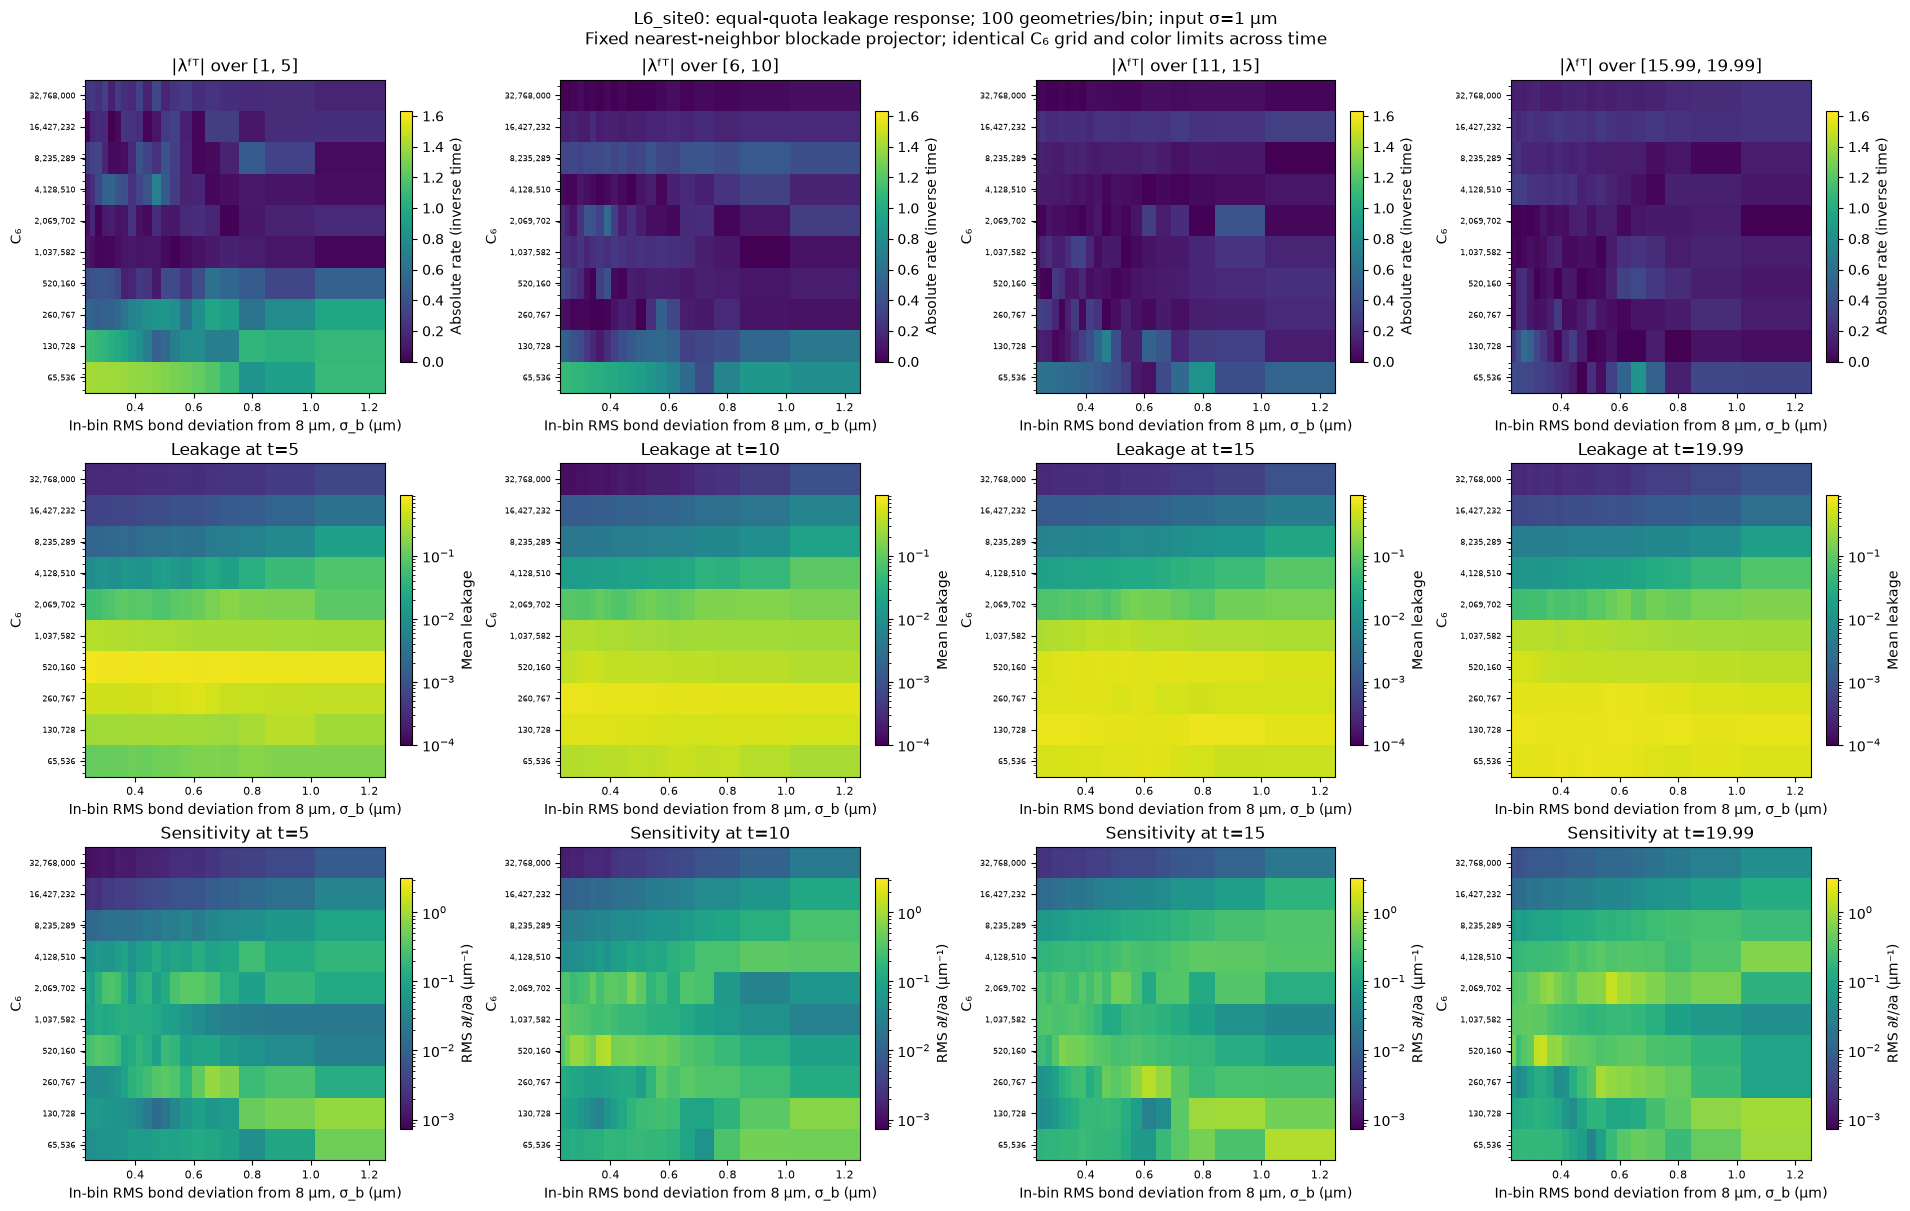

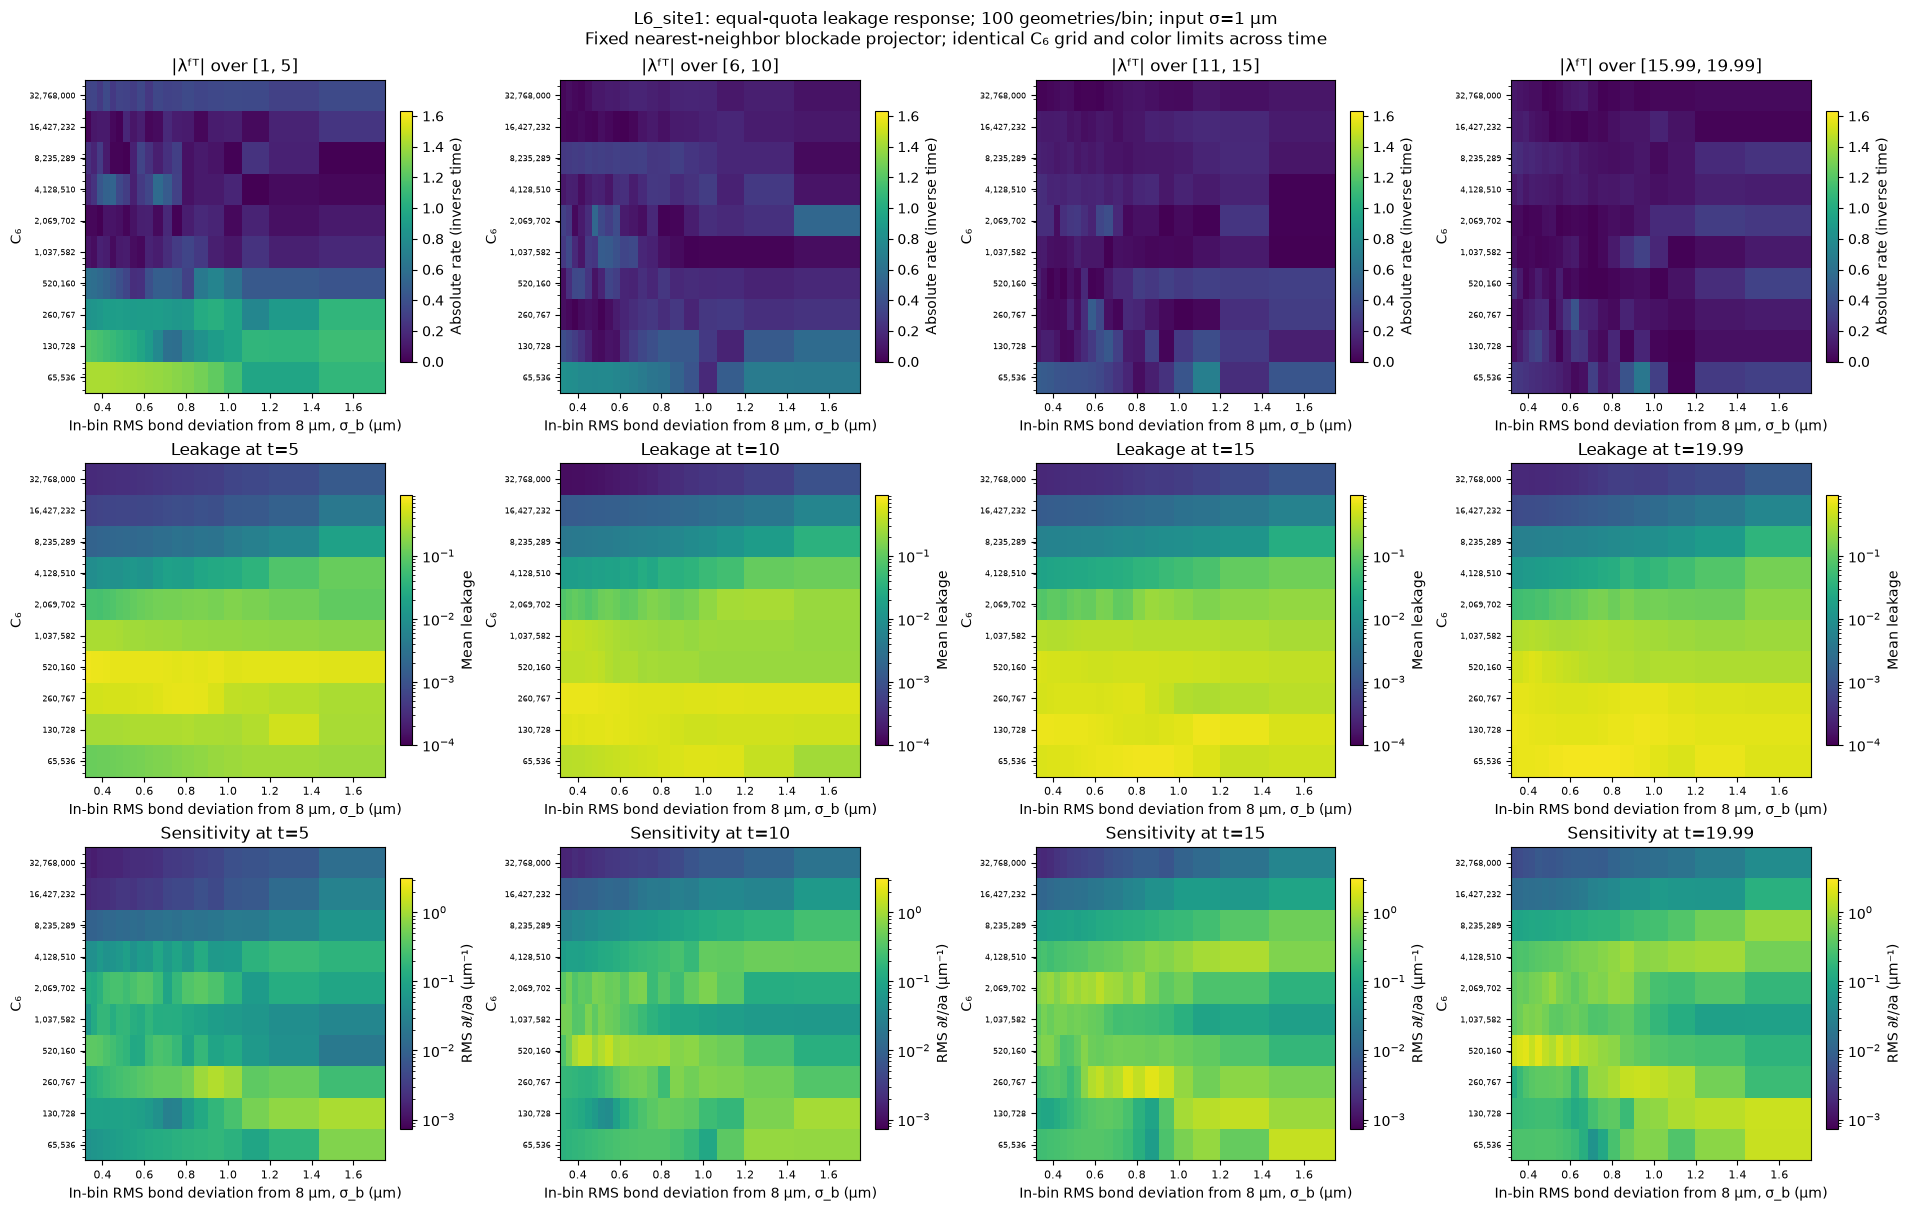

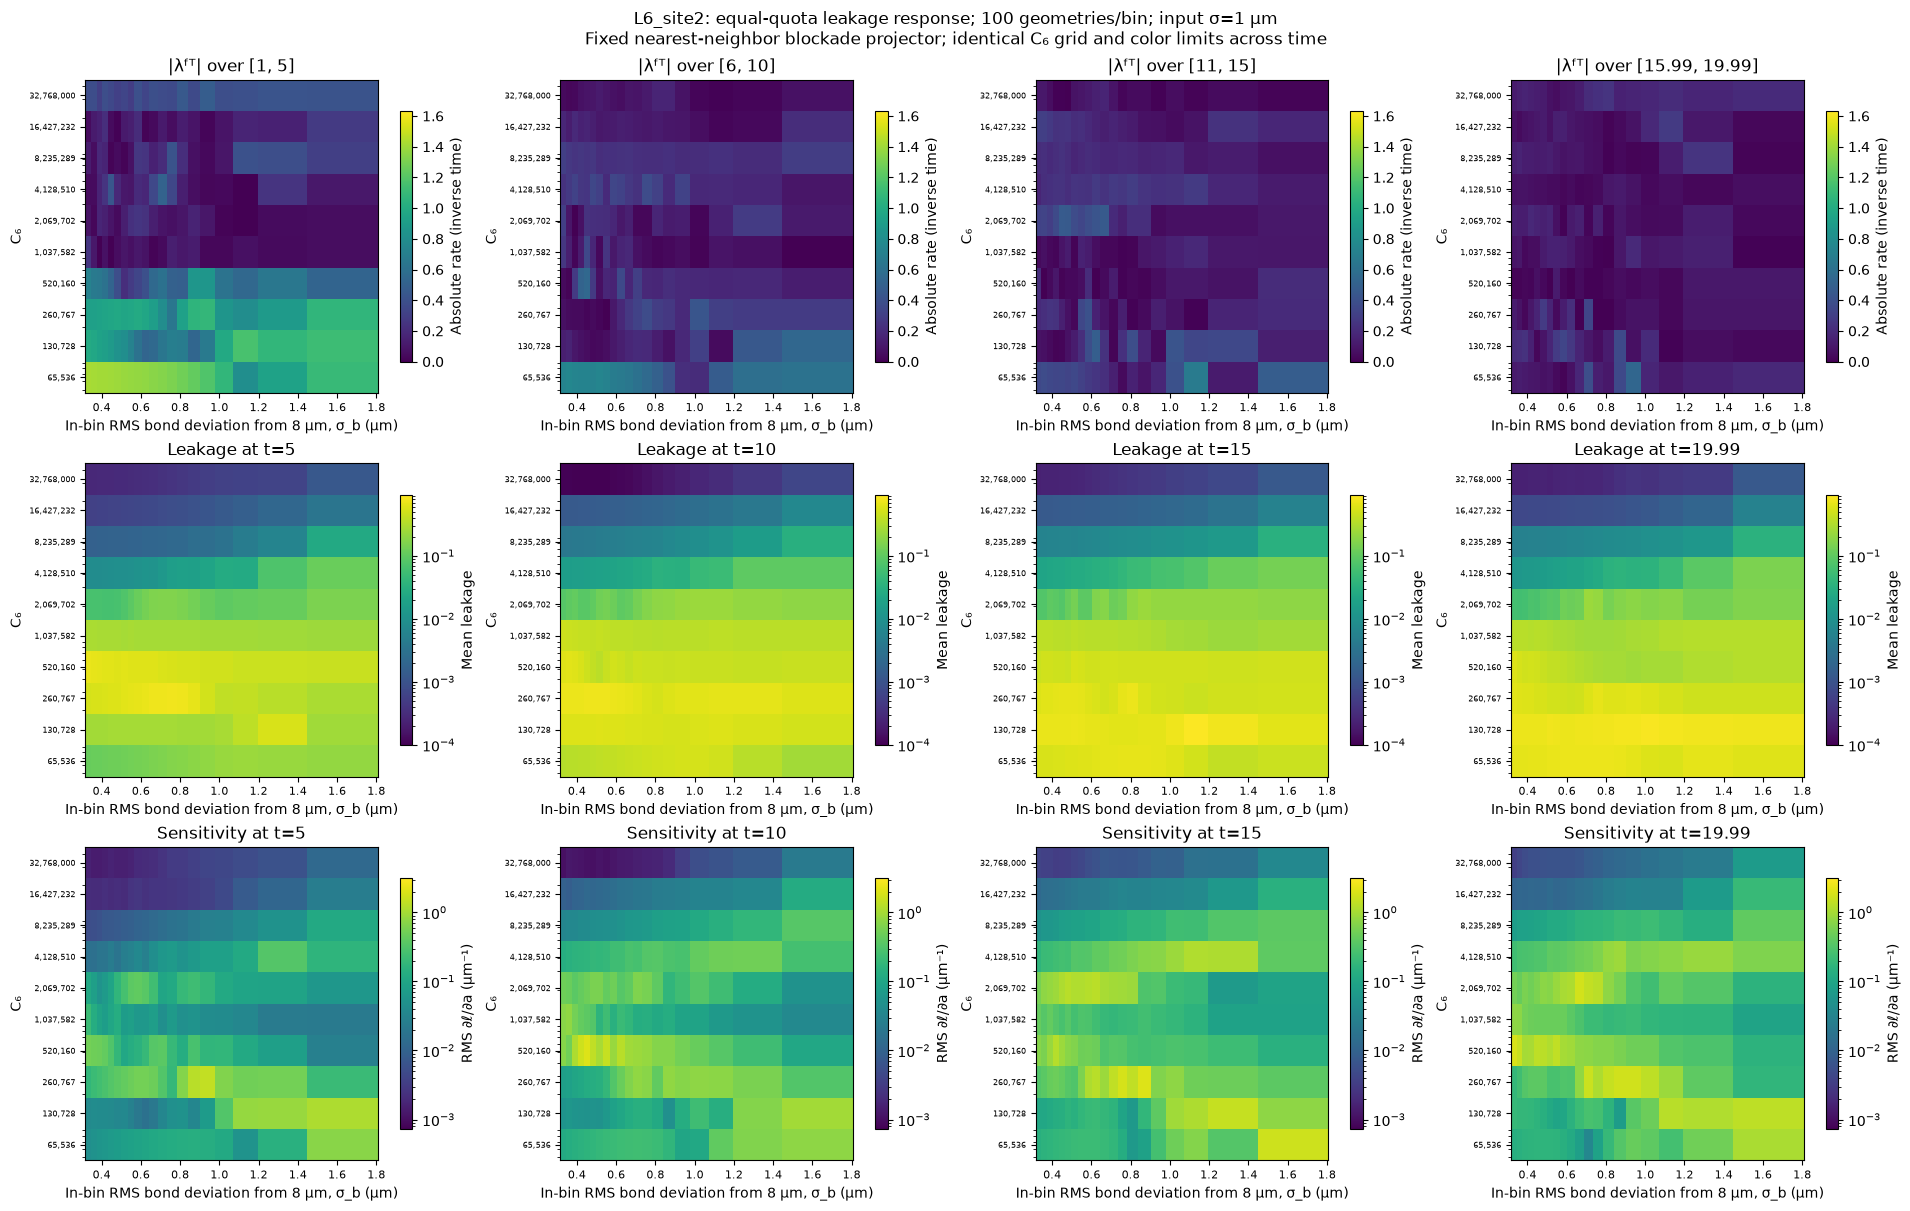

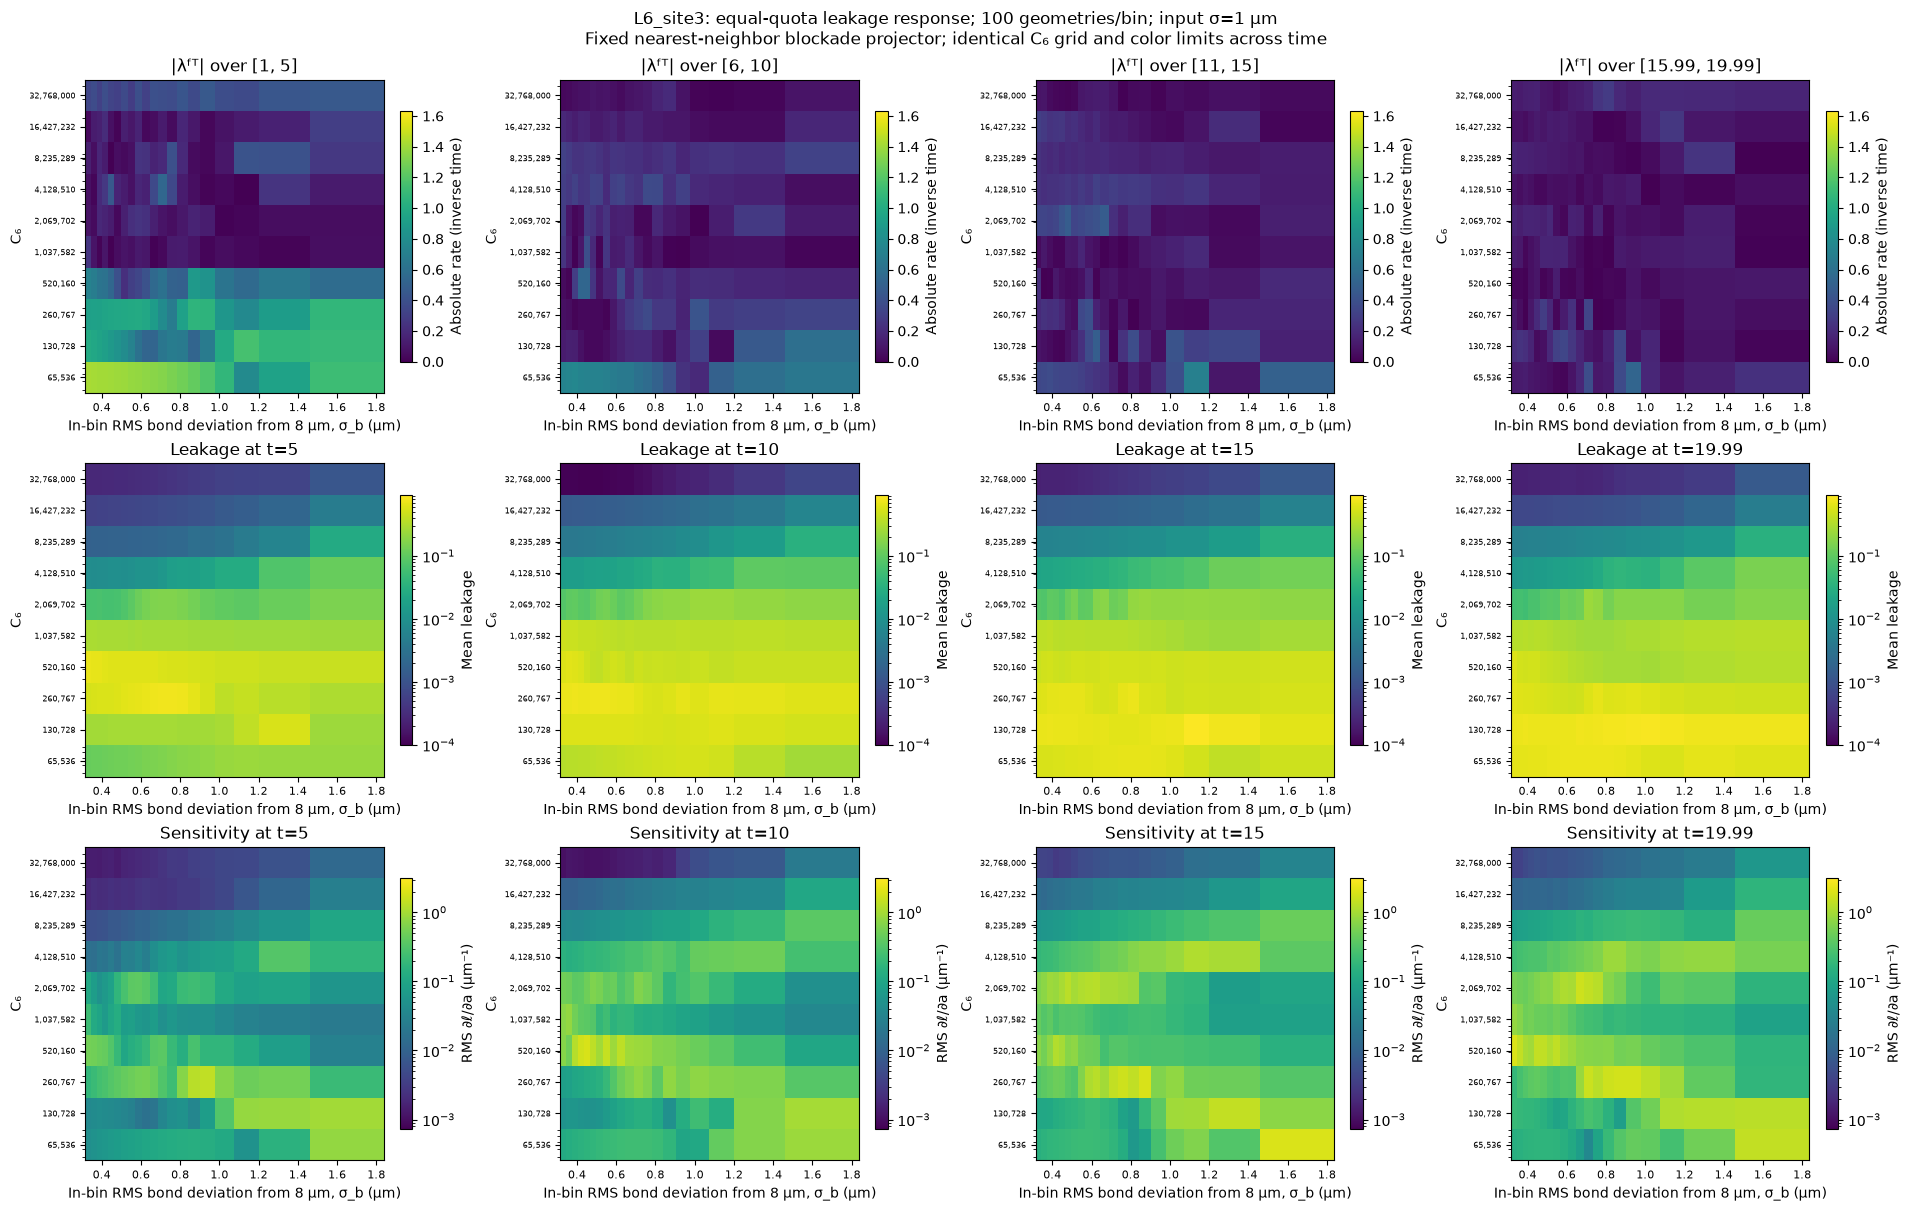

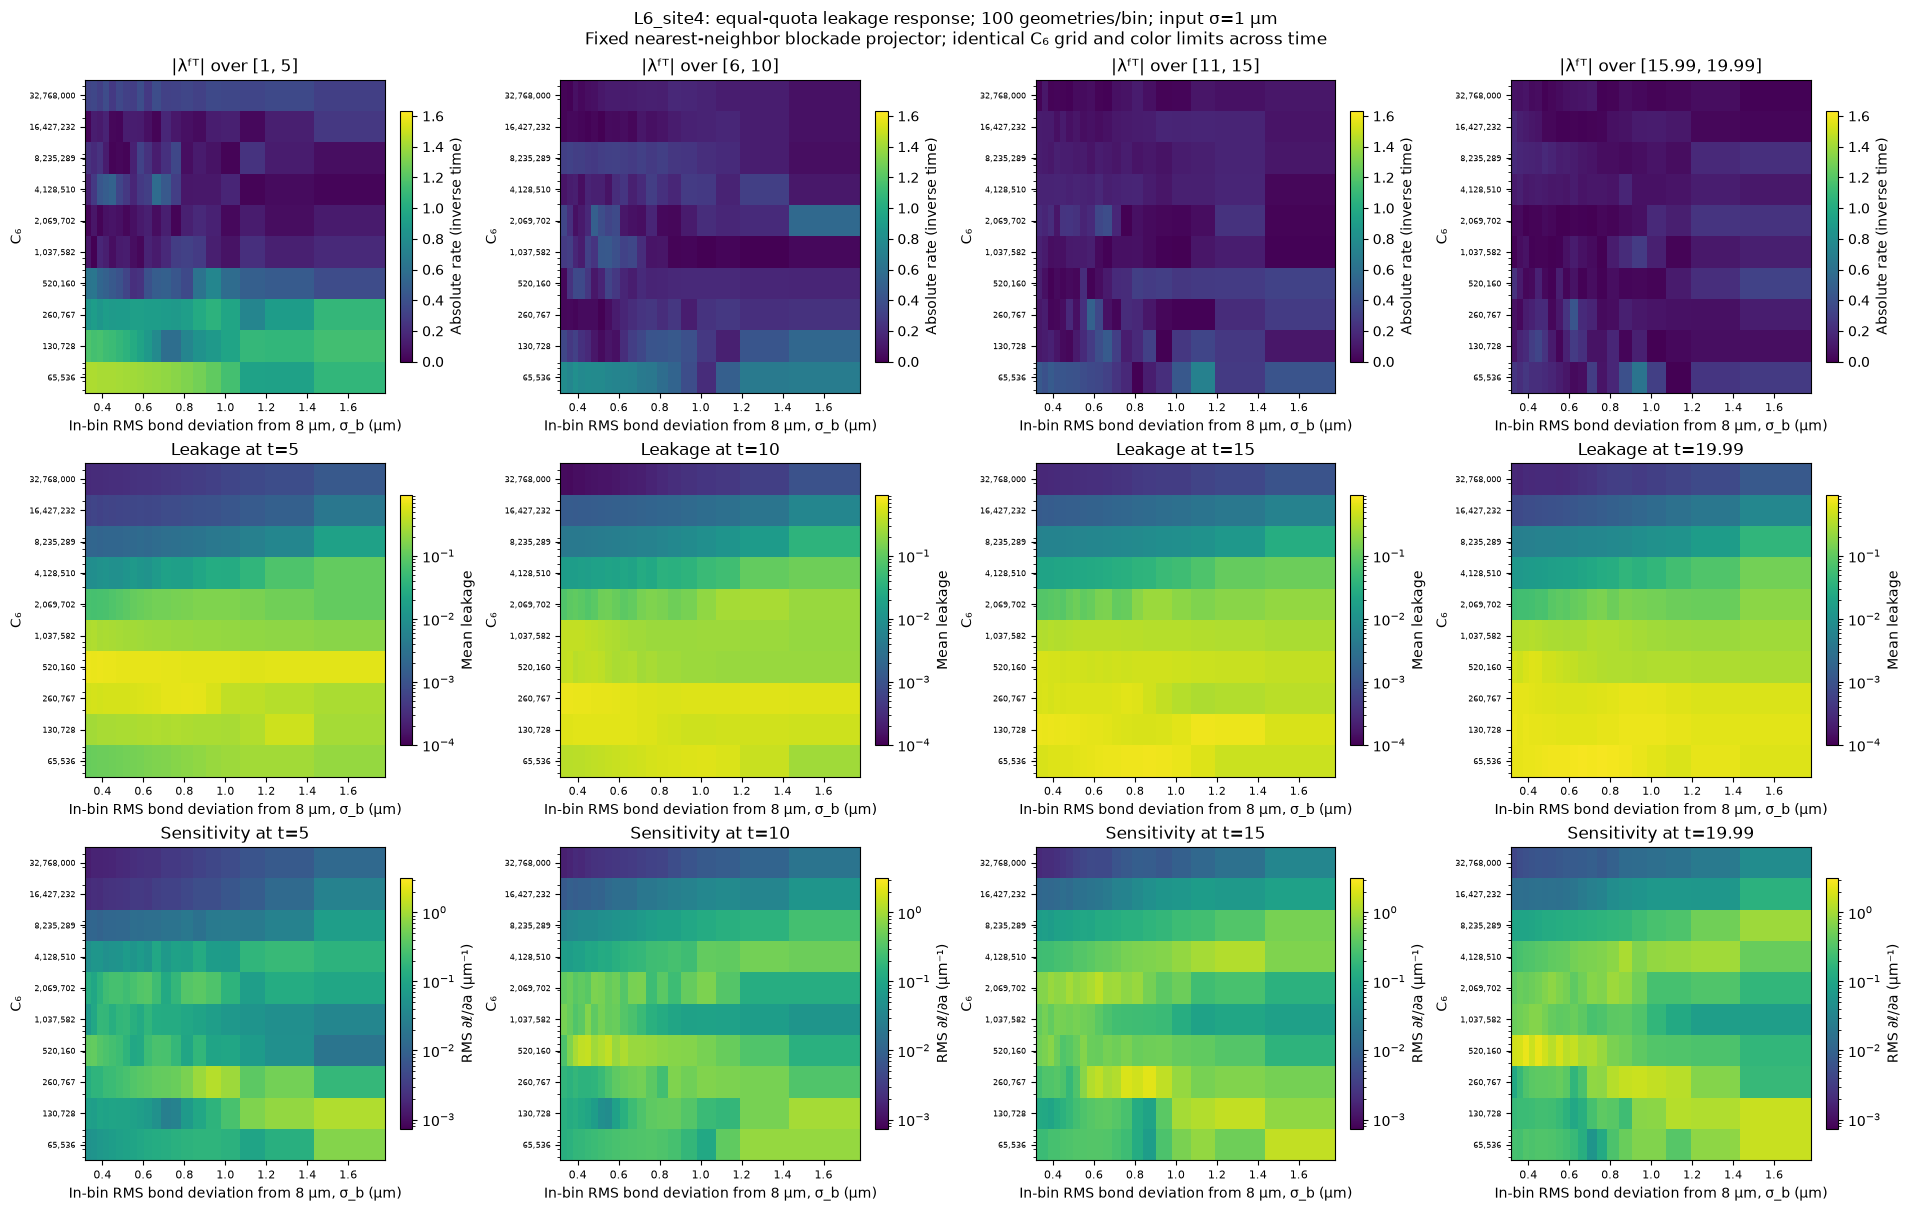

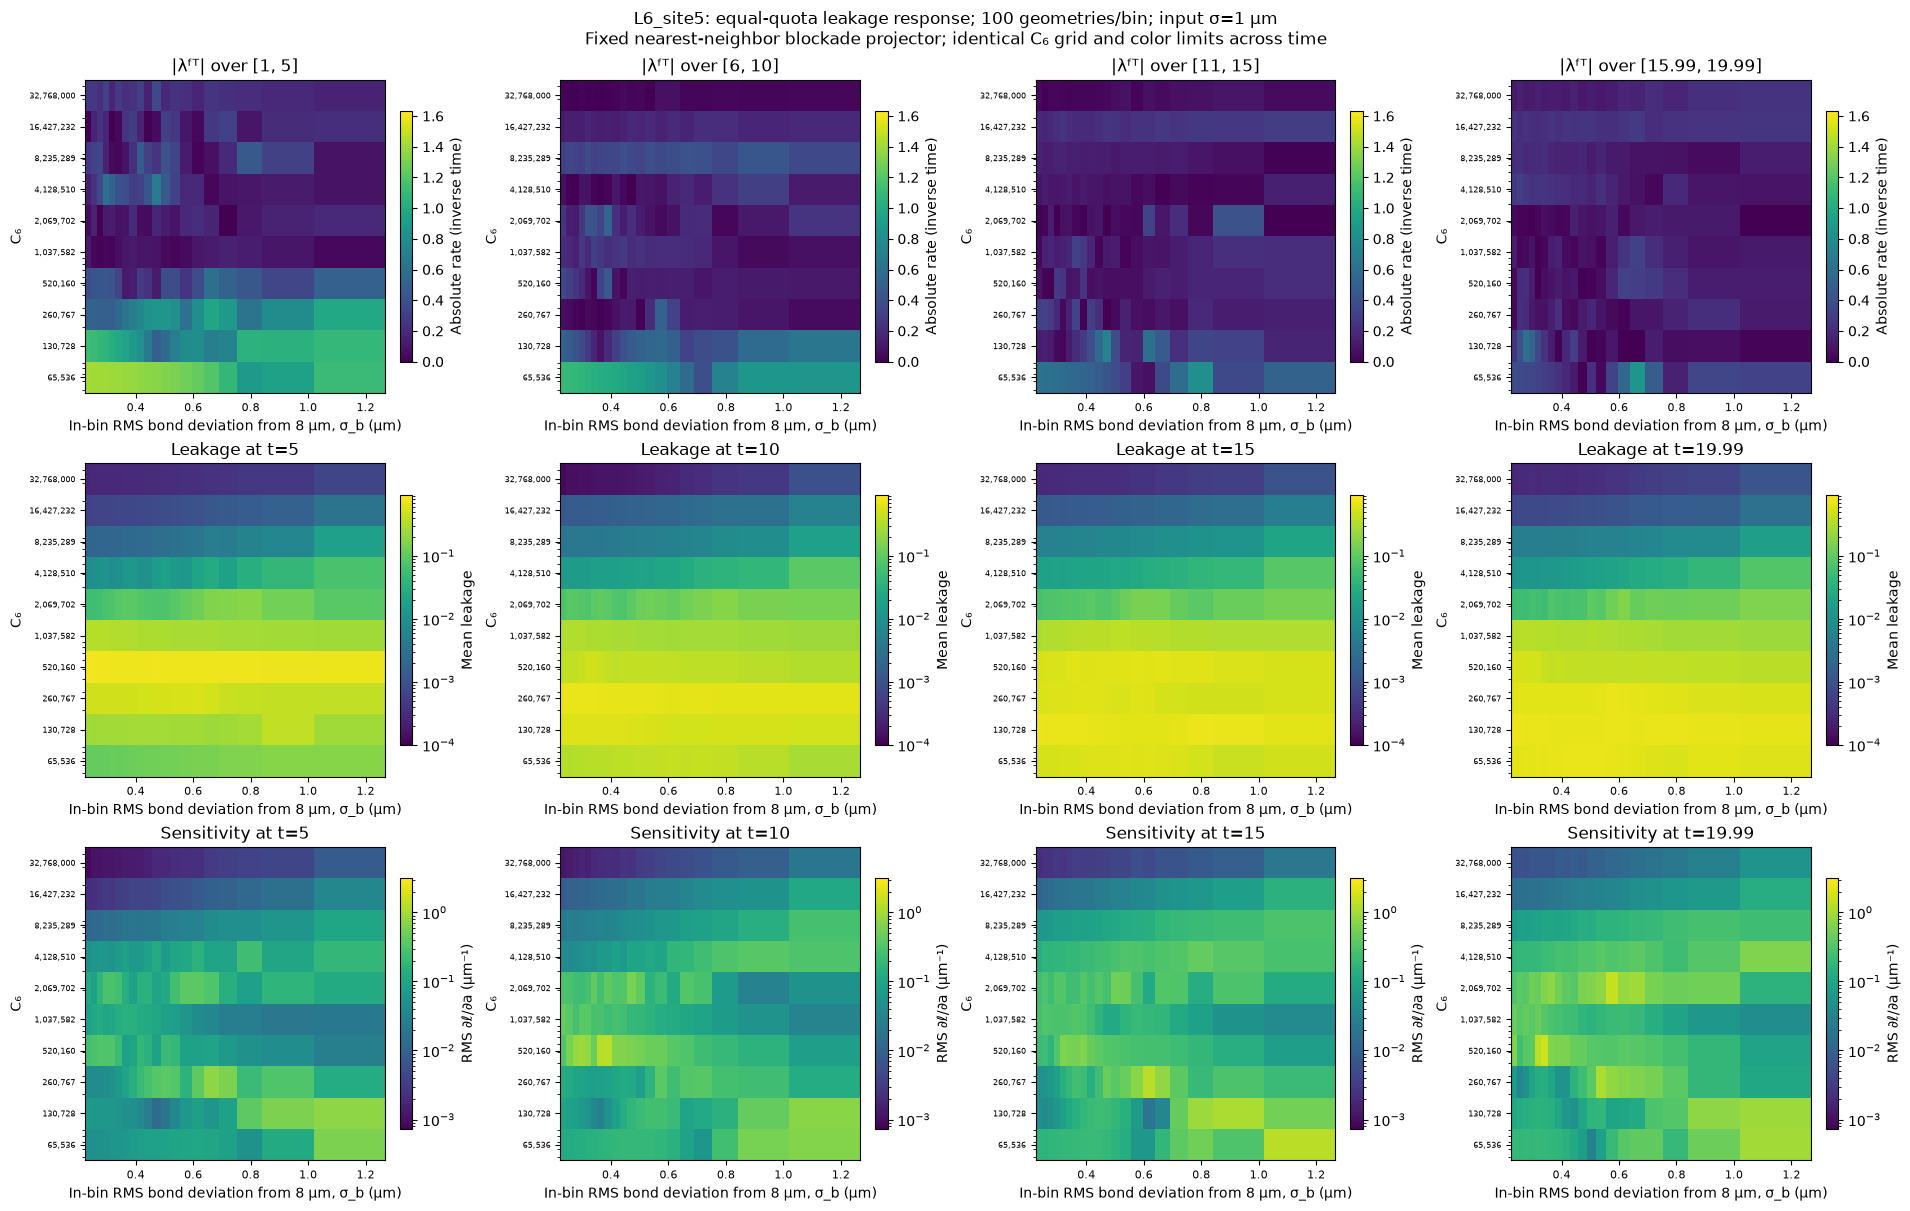

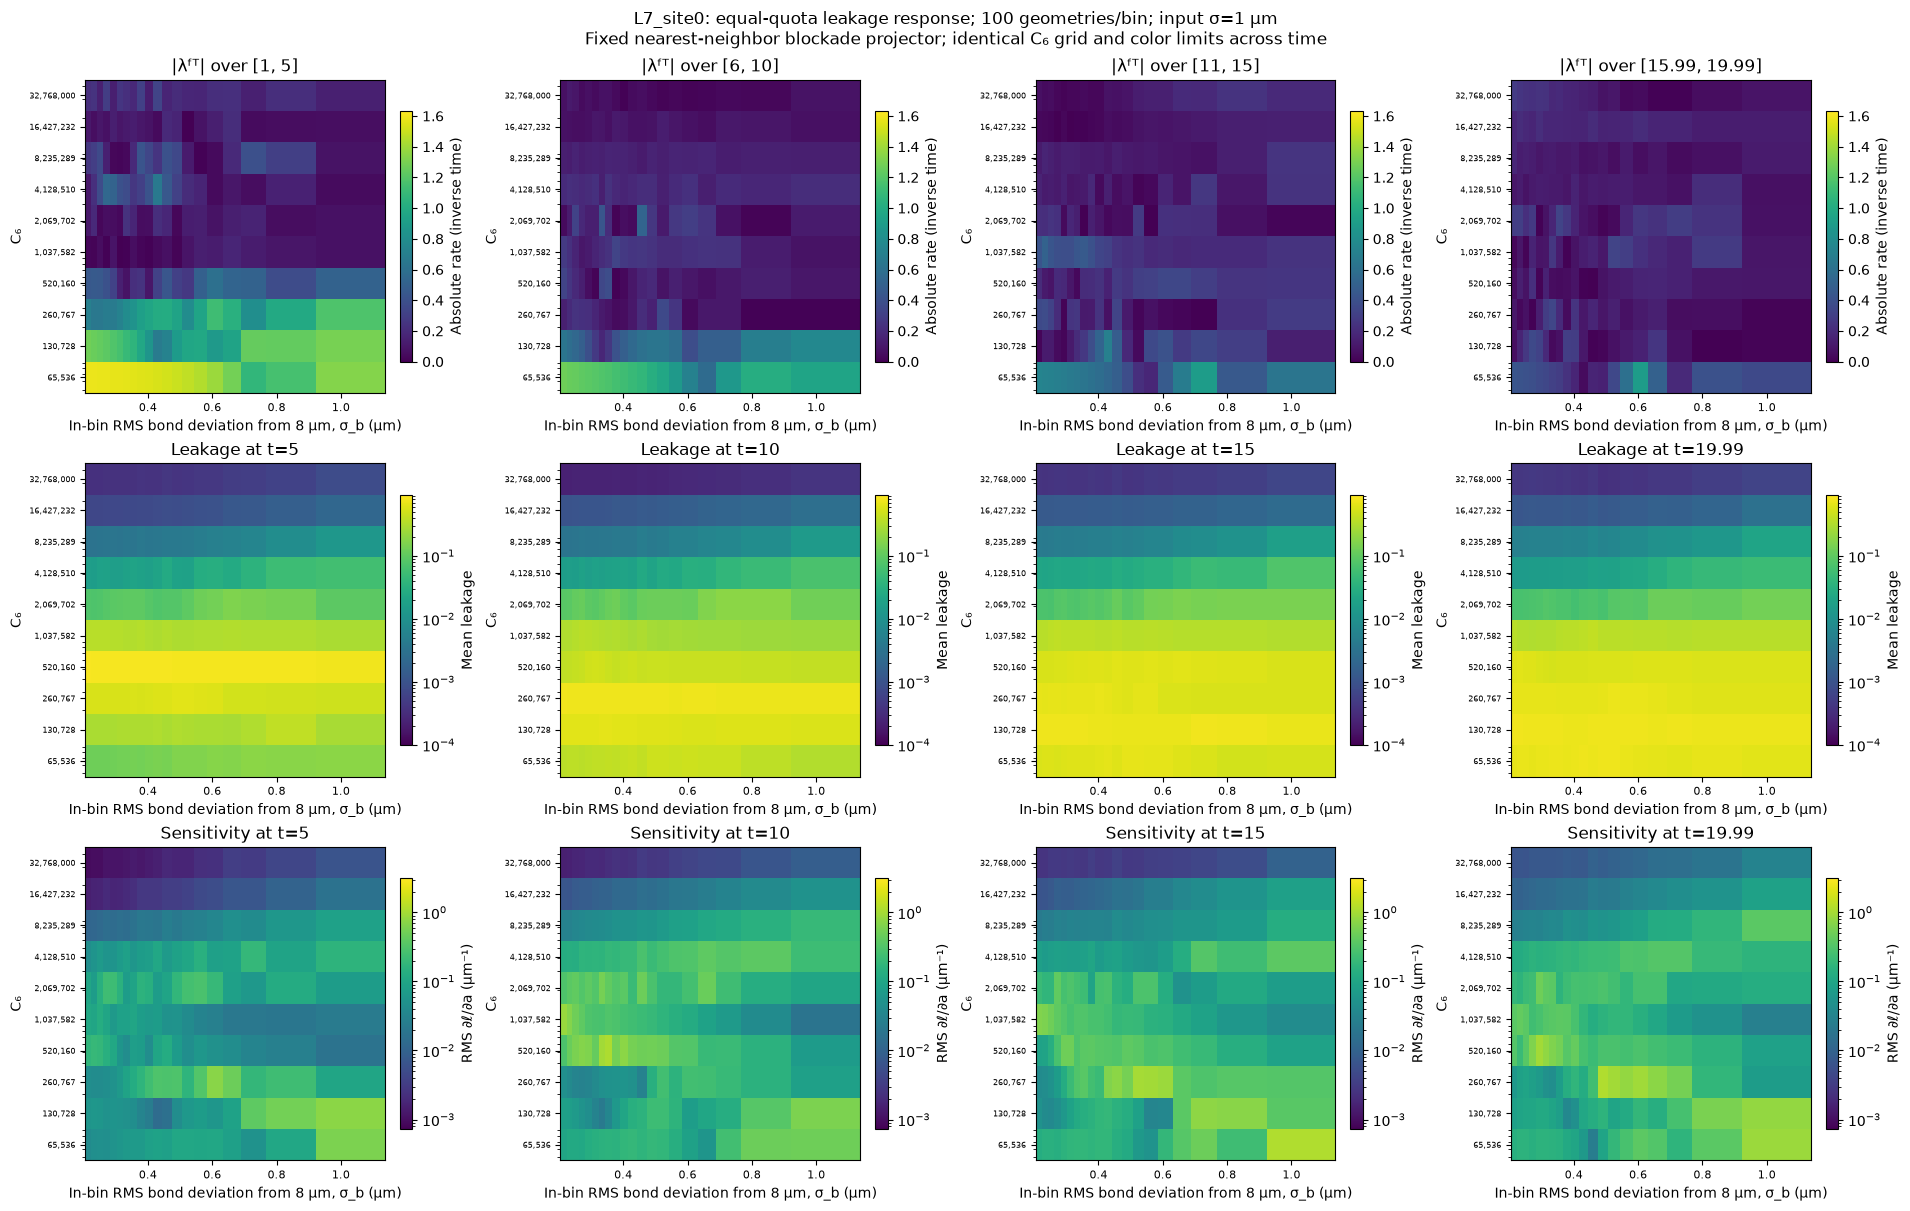

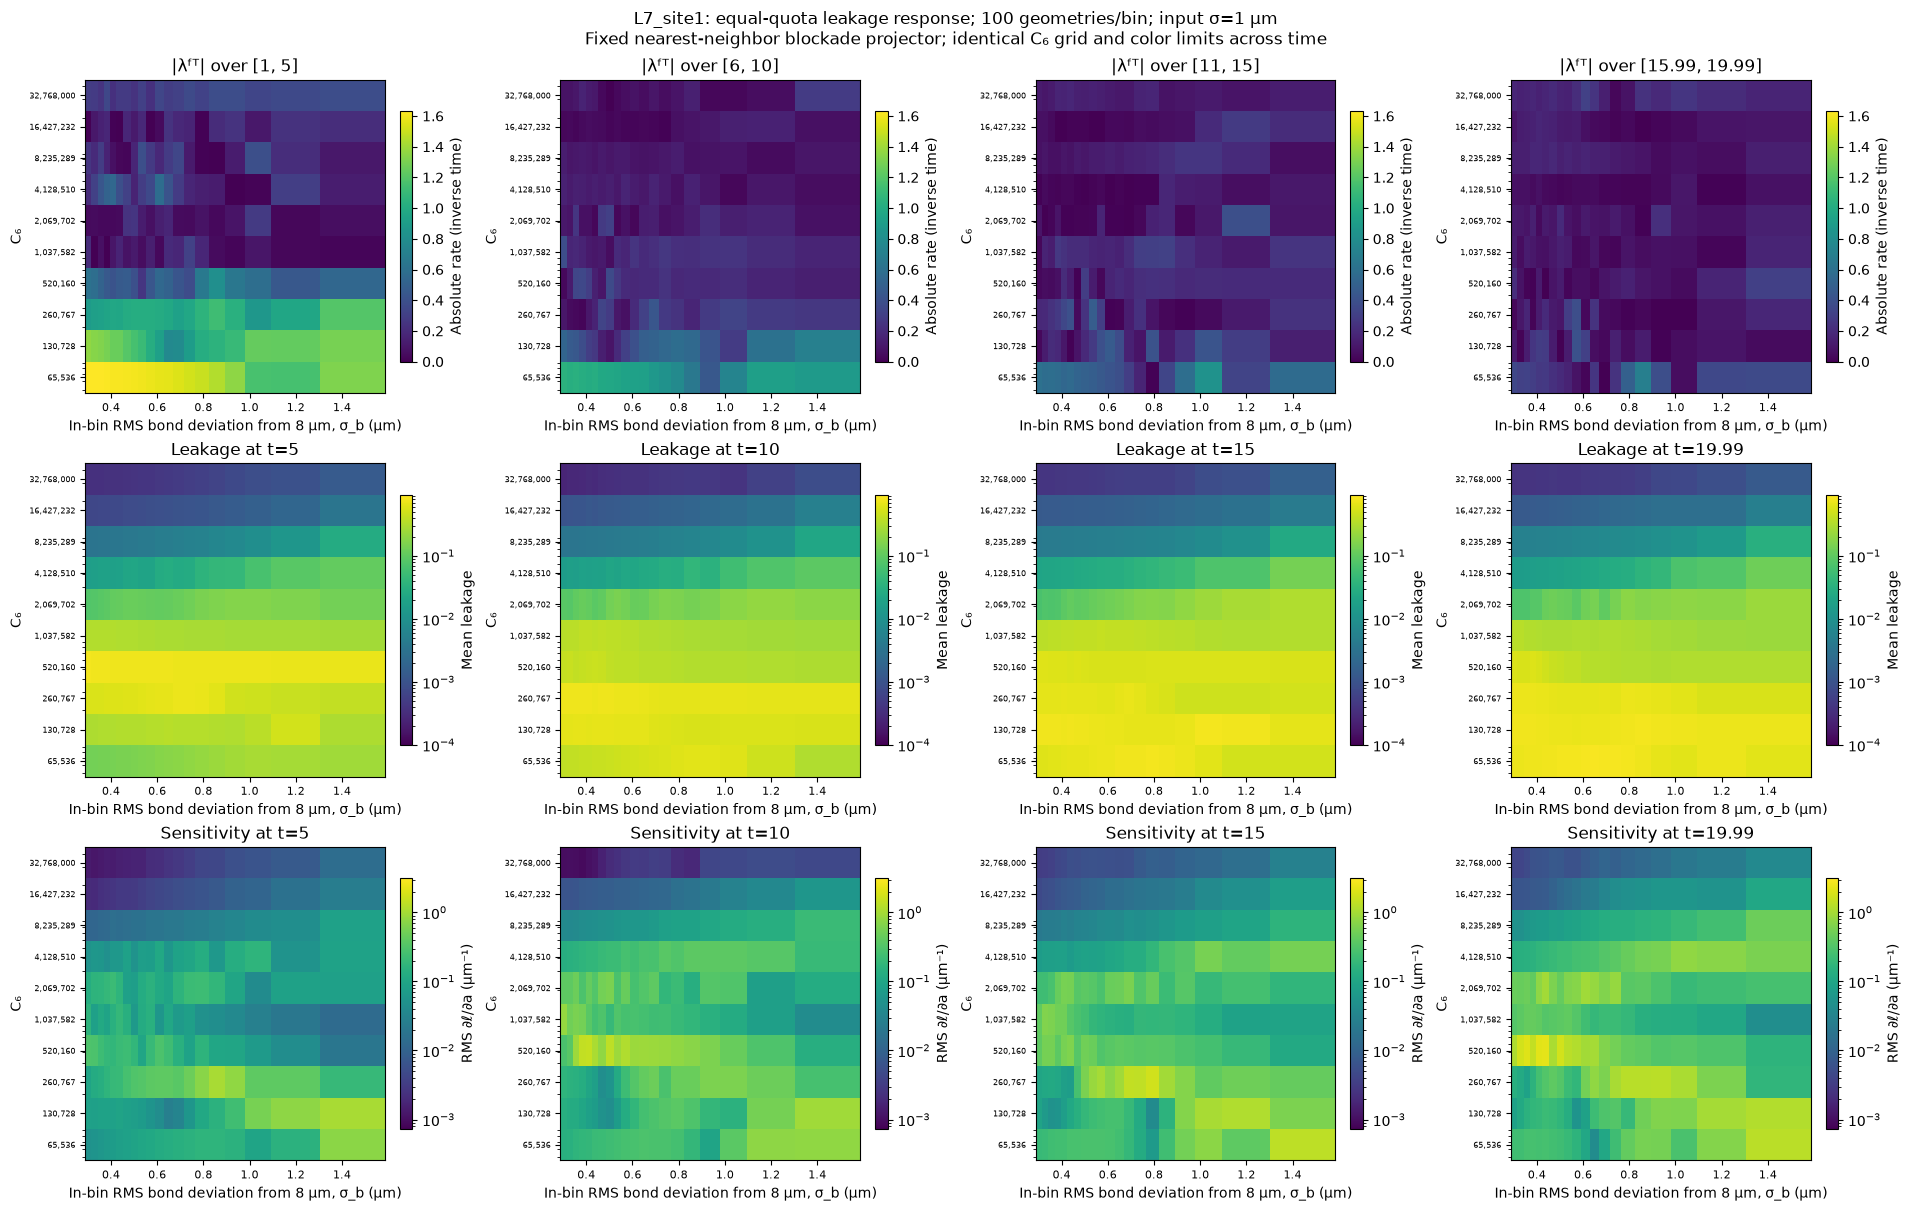

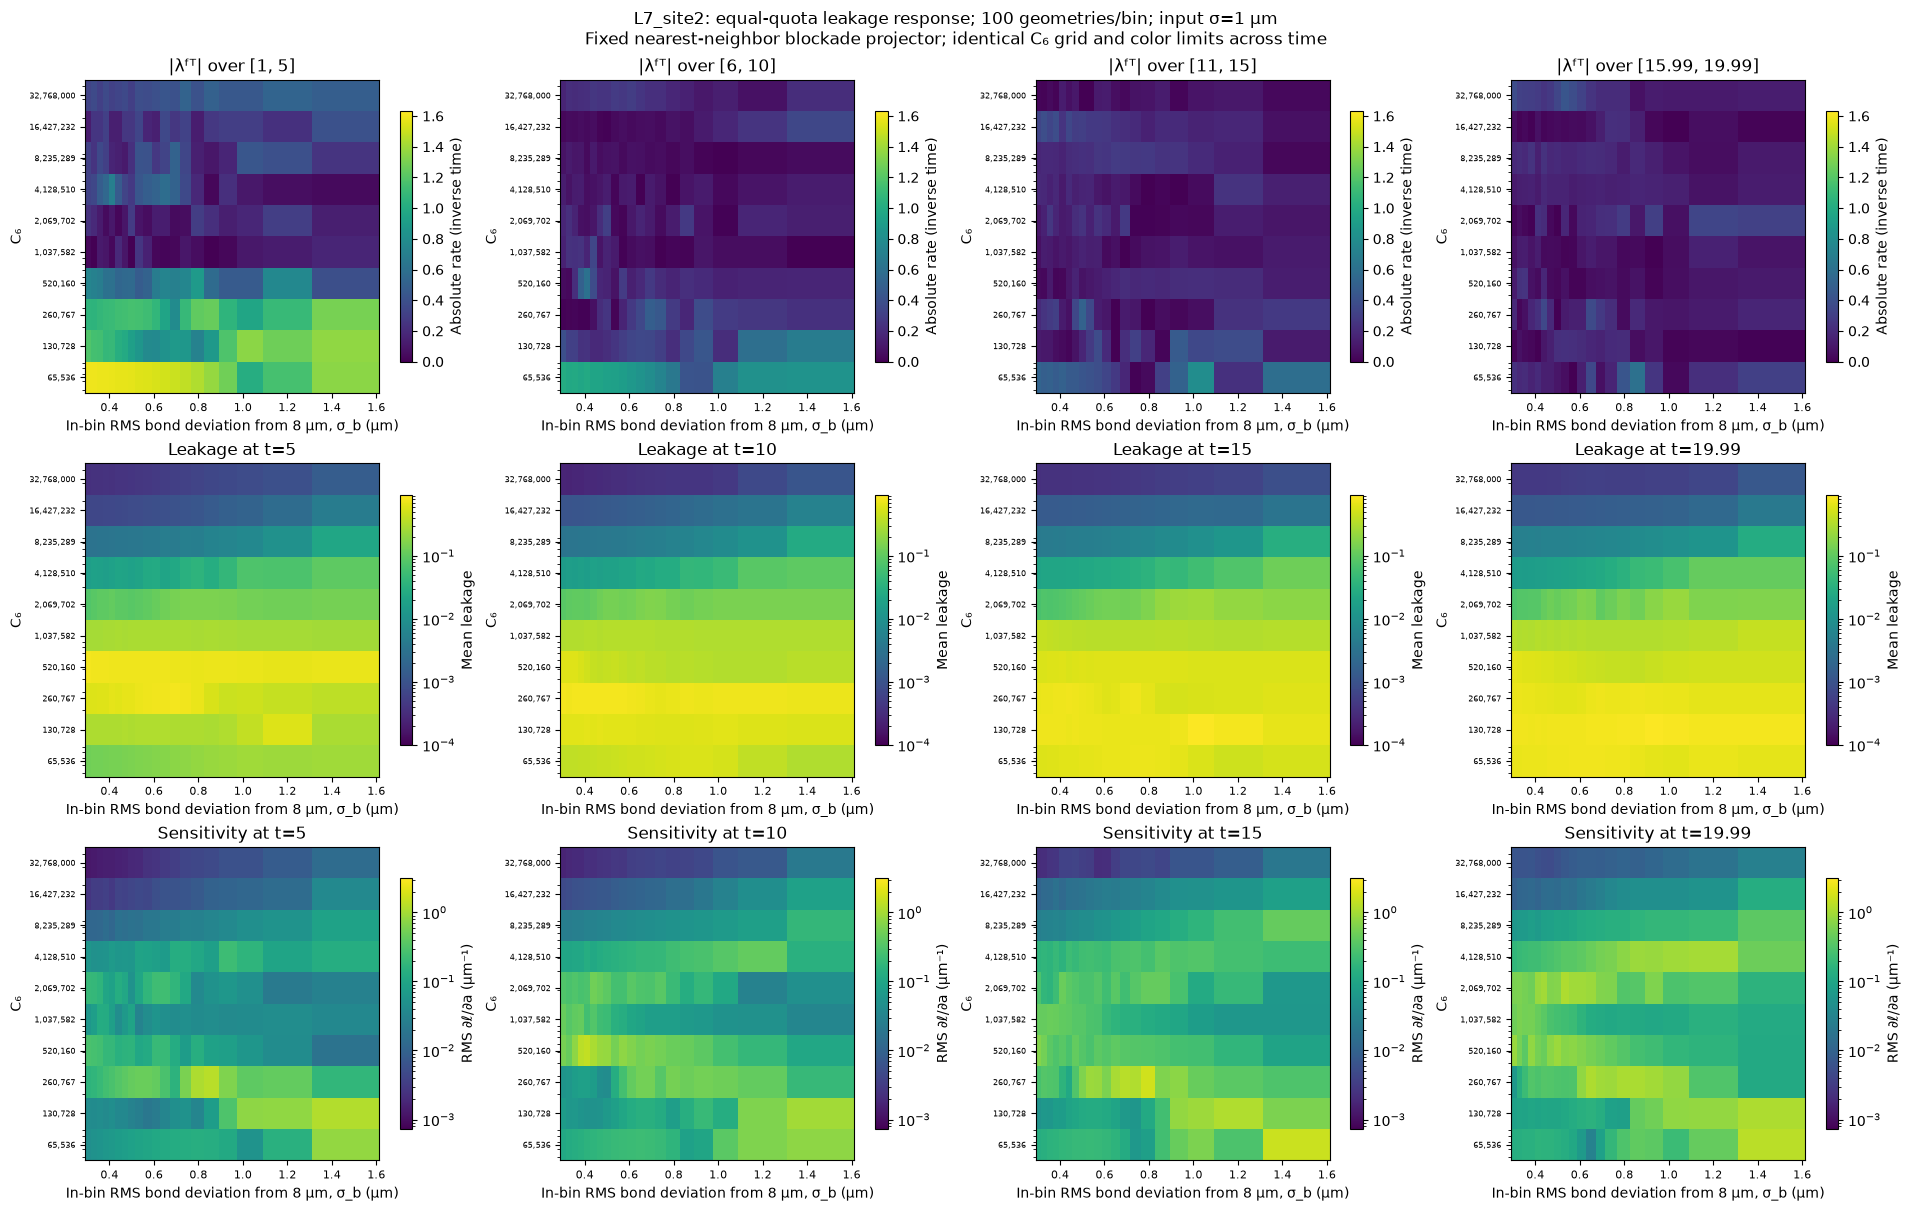

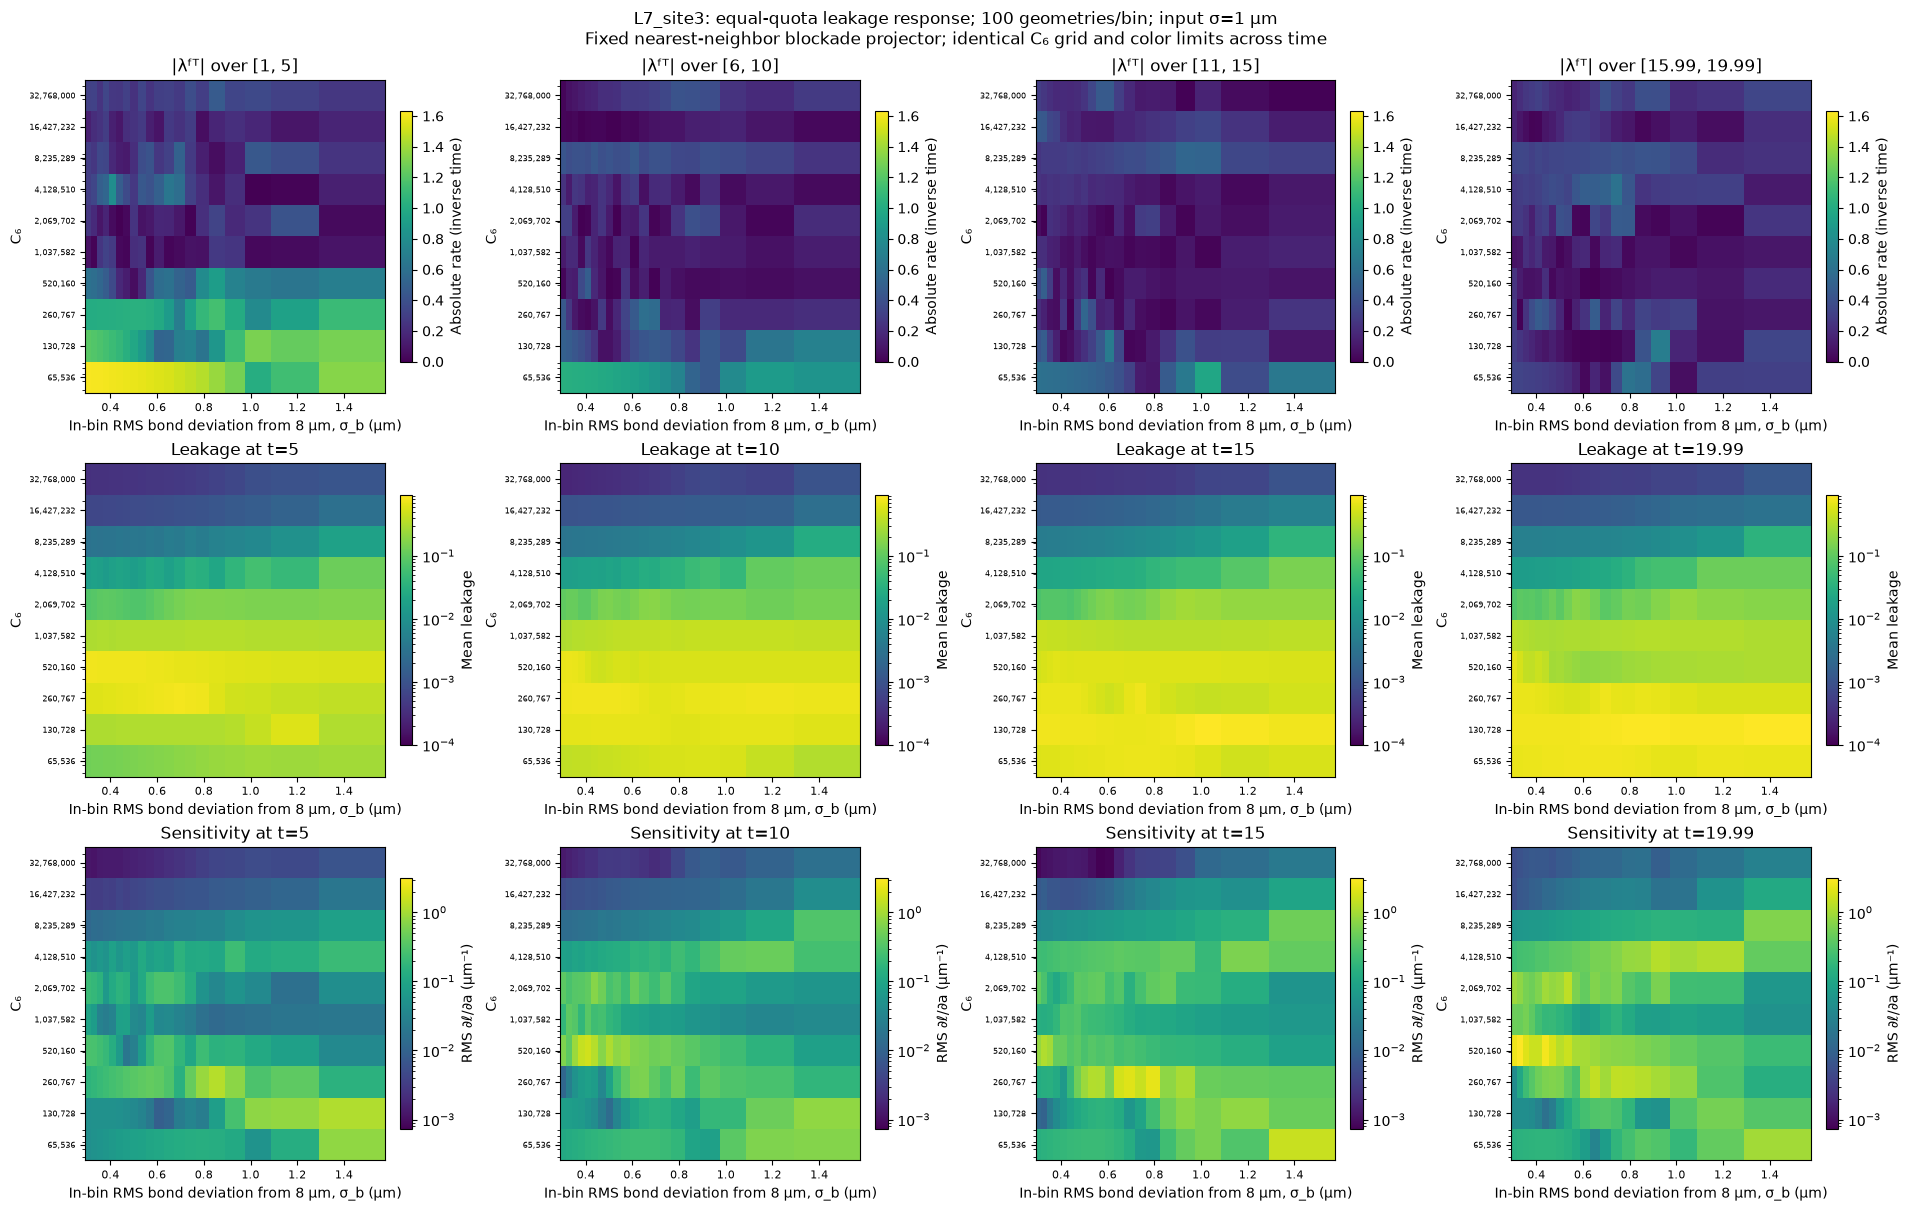

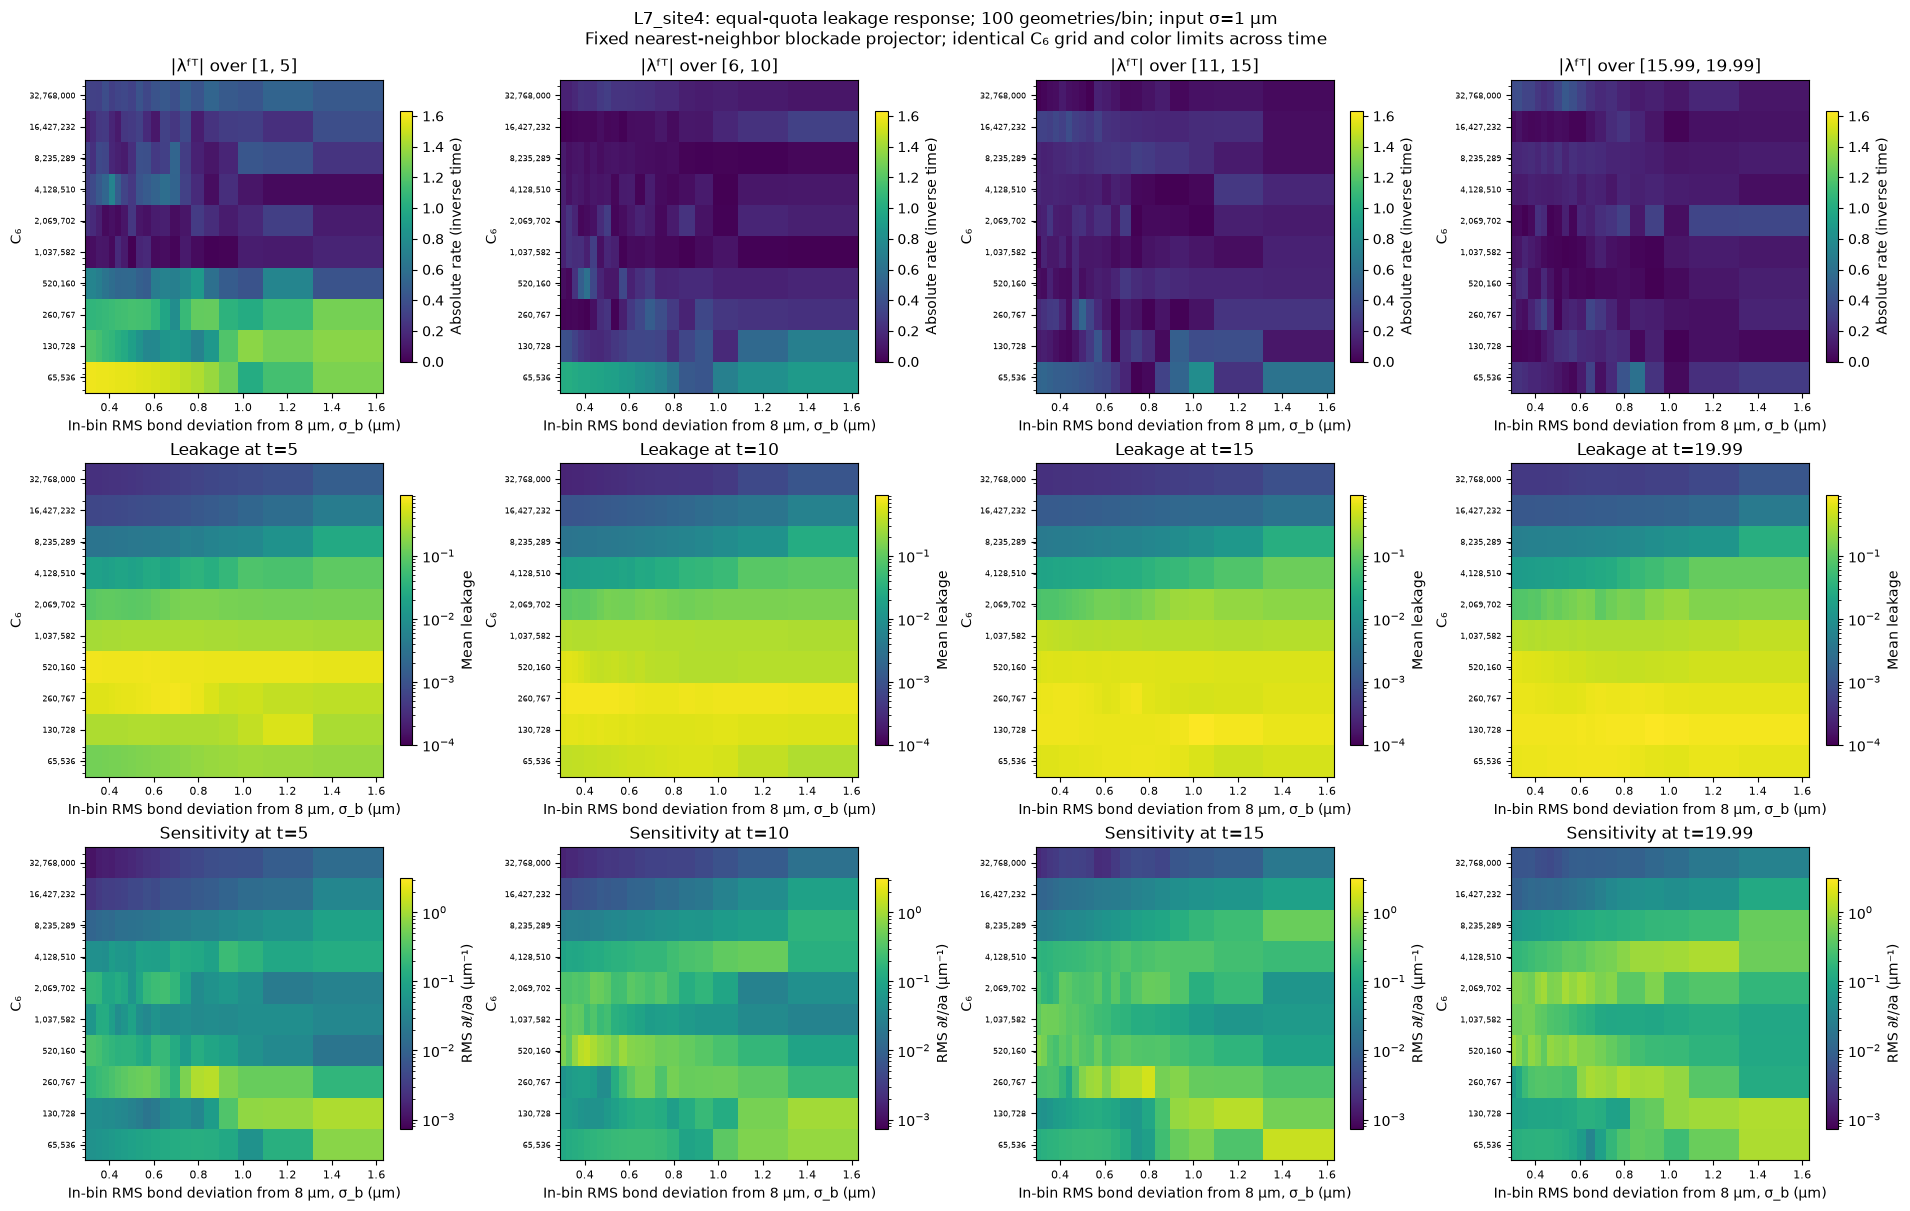

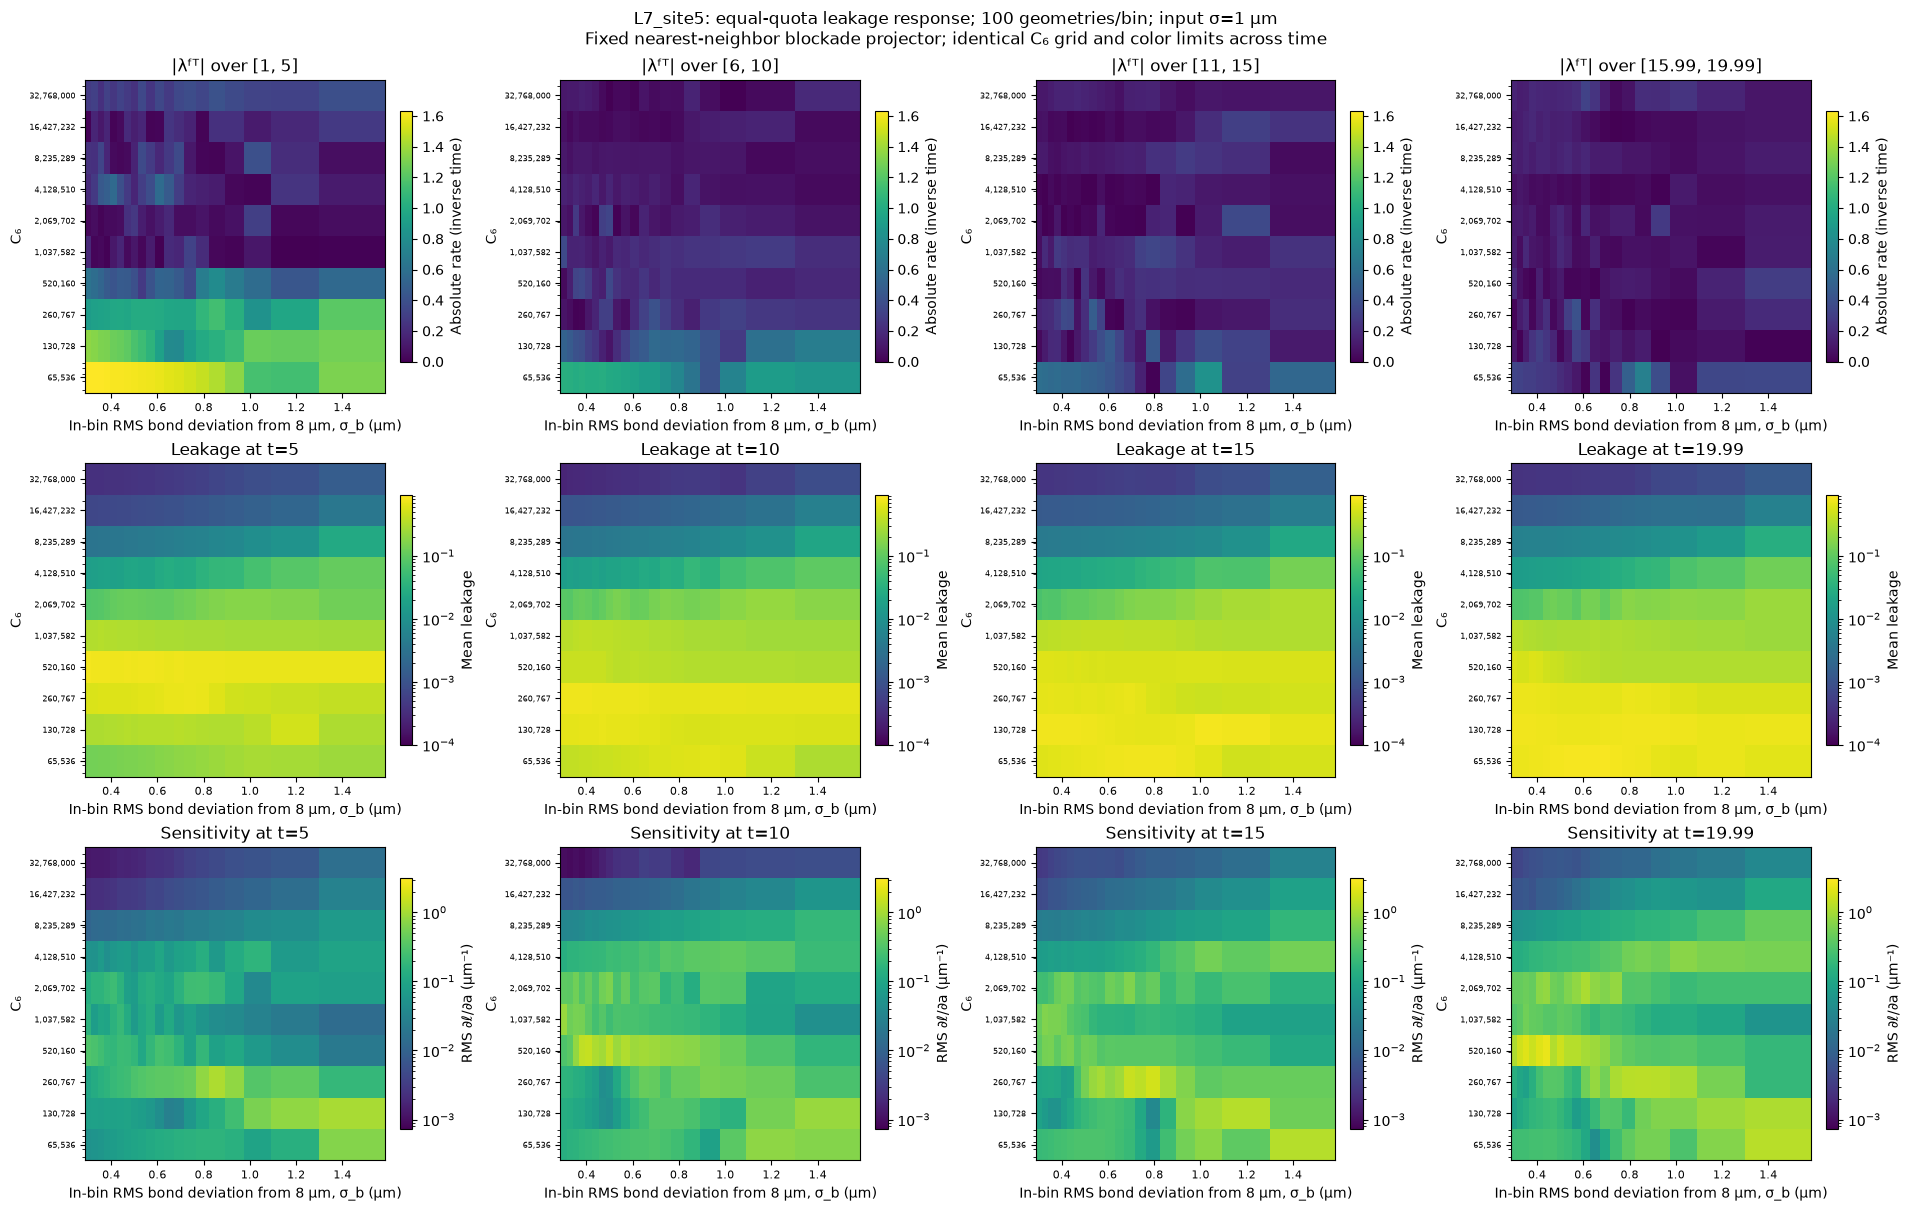

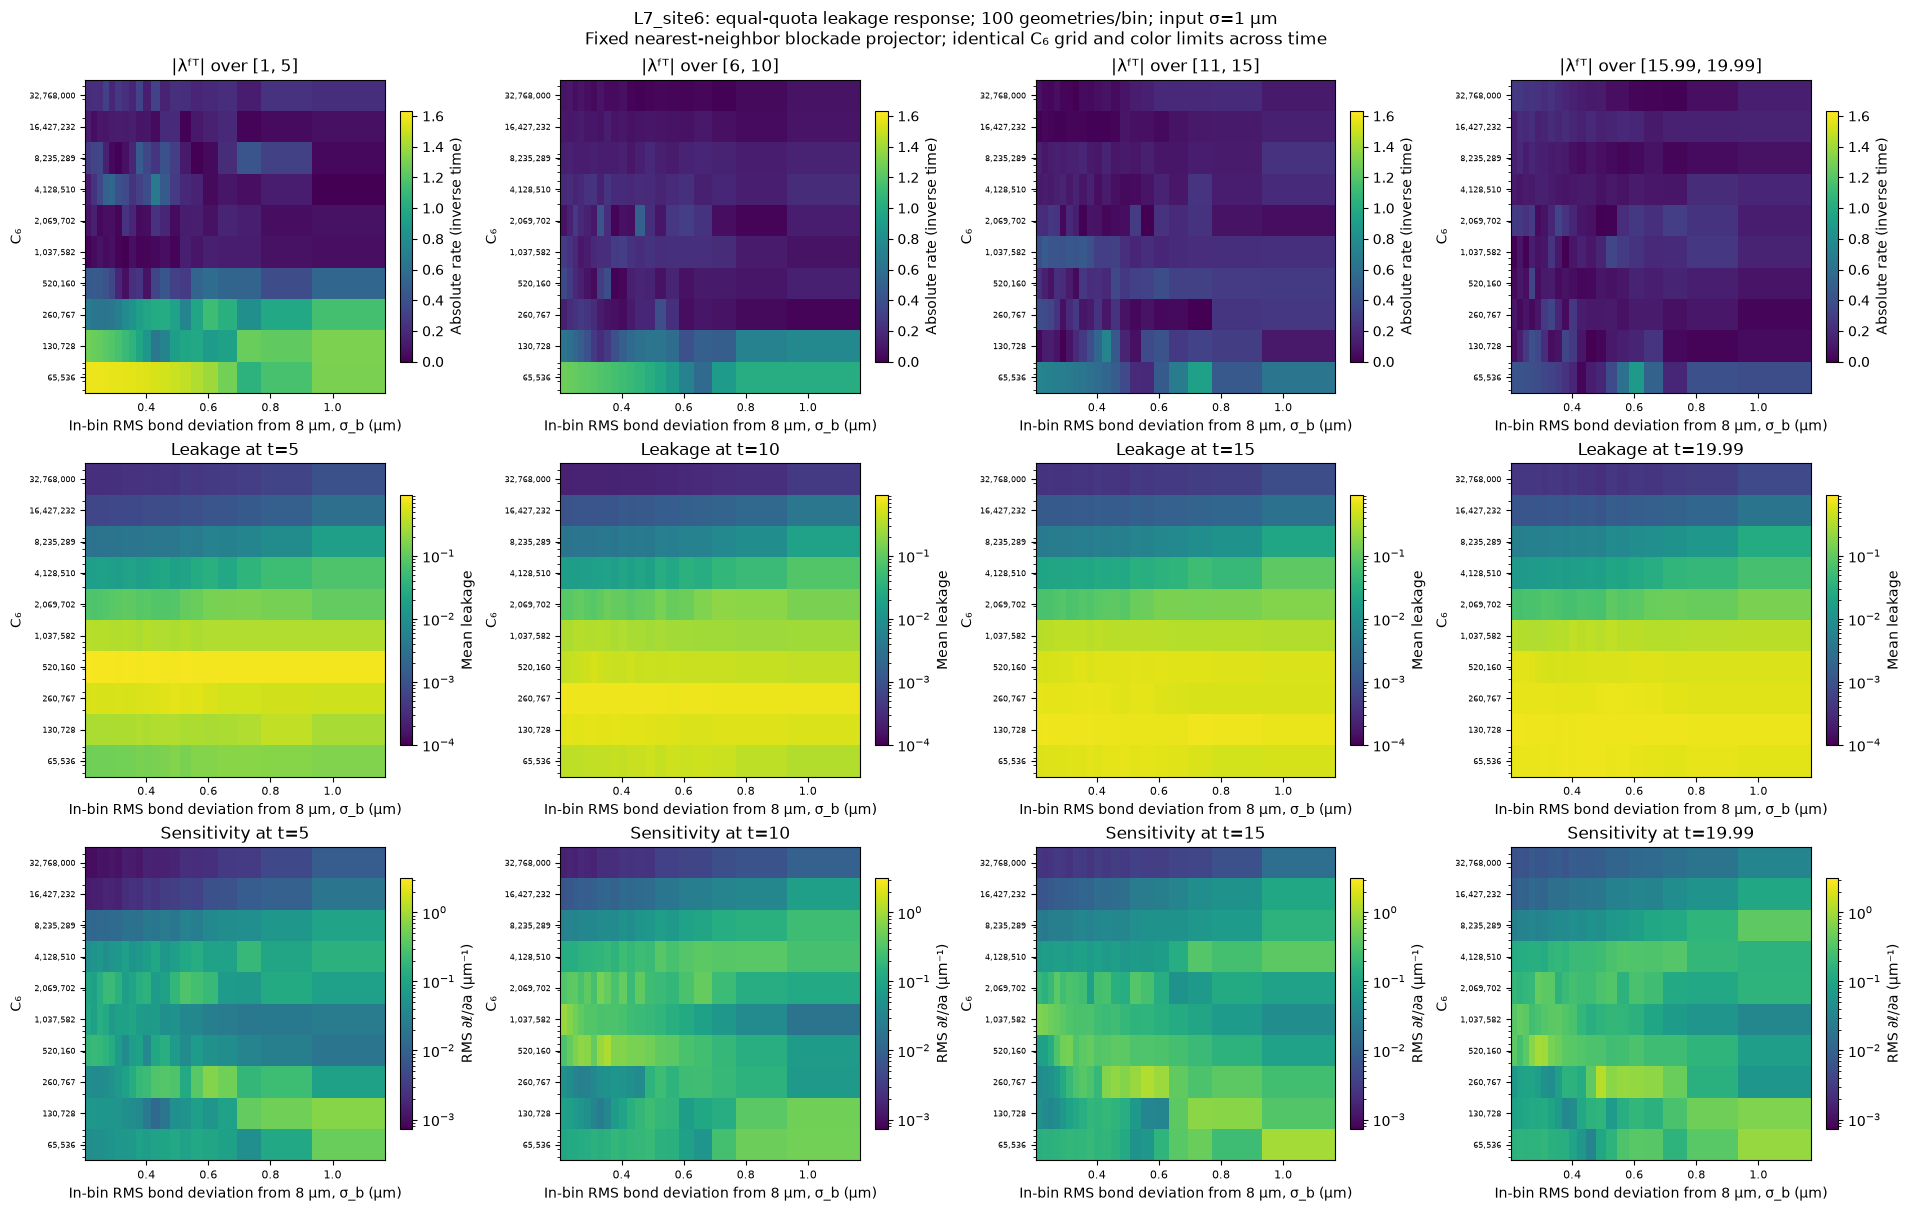

In [2]:
with PdfPages(figdir/'time_resolved_atlas.pdf') as atlas:
    for key in keys:
        fig,axes=plt.subplots(3,4,figsize=(19,12),constrained_layout=True)
        for col,t in enumerate(snapshots):
            a,b=data['windows'][col]
            specifications=[(data[key+'_lambda_absolute'][:,:,col],norm_rate,f'|λᶠᵀ| over [{a:g}, {b:g}]','Absolute rate (inverse time)'),
                            (data[key+'_mean_leakage'][:,:,time_indices[col]],norm_leak,f'Leakage at t={t:g}','Mean leakage'),
                            (data[key+'_D'][:,:,time_indices[col]],norm_d,f'Sensitivity at t={t:g}','RMS ∂ℓ/∂a (µm⁻¹)')]
            for row,(z,norm,title,label) in enumerate(specifications):
                image=panel(axes[row,col],key,z,norm,title)
                fig.colorbar(image,ax=axes[row,col],label=label,shrink=.8)
        fig.suptitle(f'{key}: equal-quota leakage response; 100 geometries/bin; input σ=1 µm\nFixed nearest-neighbor blockade projector; identical C₆ grid and color limits across time')
        save(fig,key+'_time_resolved',atlas)


### Integrated response and uncertainty

These panels use the full input window, t=0–19.99. Confidence intervals resample whole geometries within each site/bin; they describe finite-ensemble uncertainty. The absolute endpoint rate can be small despite large intermediate oscillations. It is not a chaos diagnostic, and a large relative rate at tiny sensitivity need not provide useful geometry information.

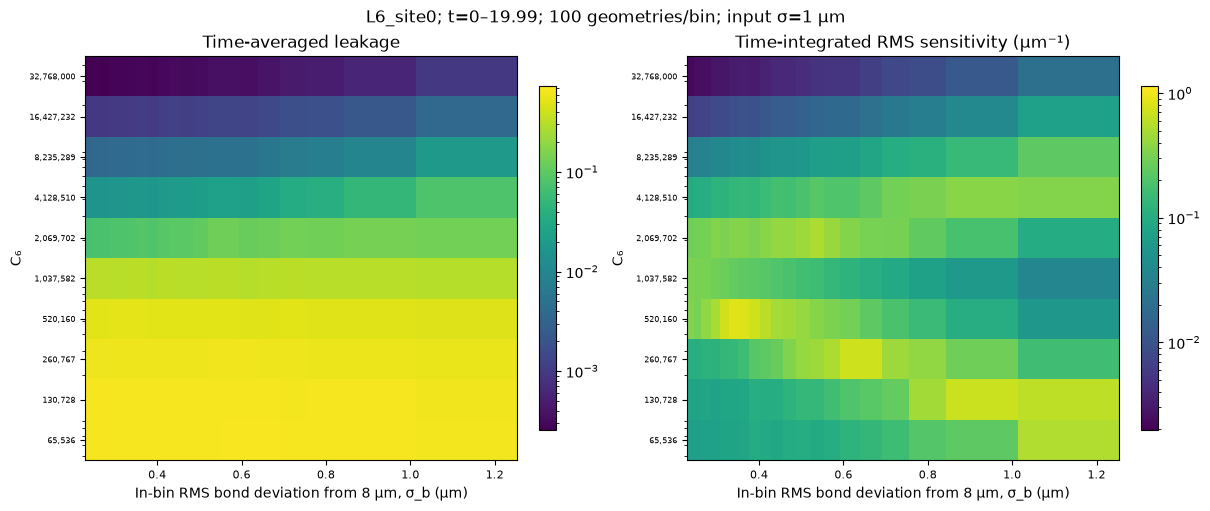

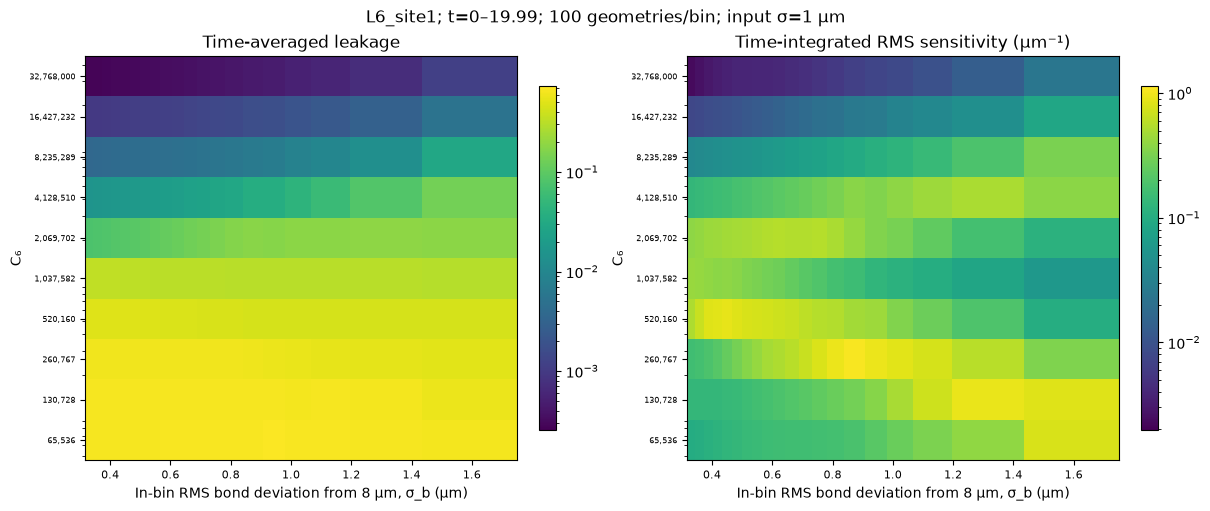

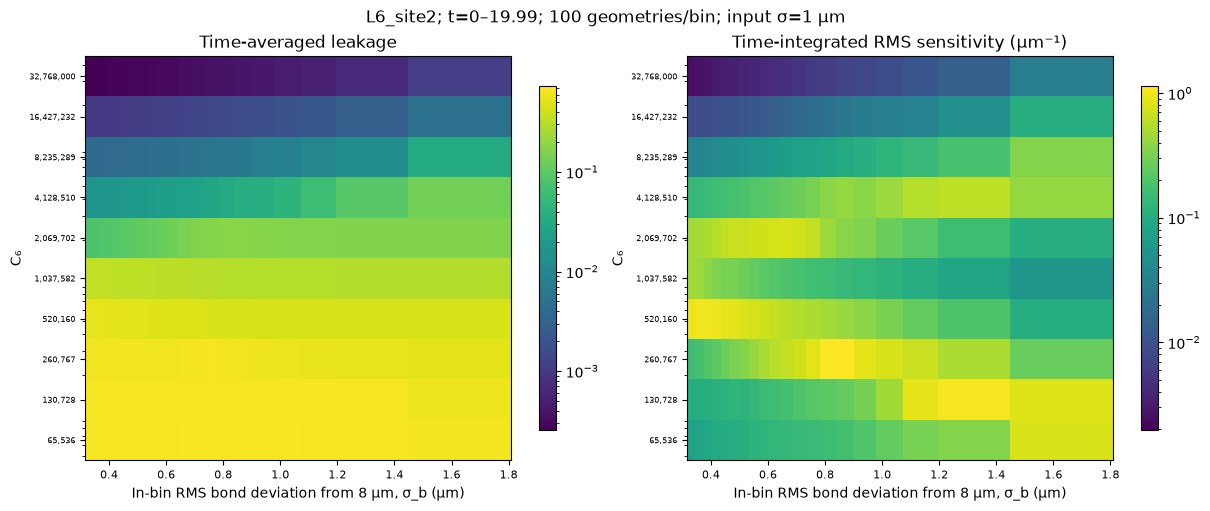

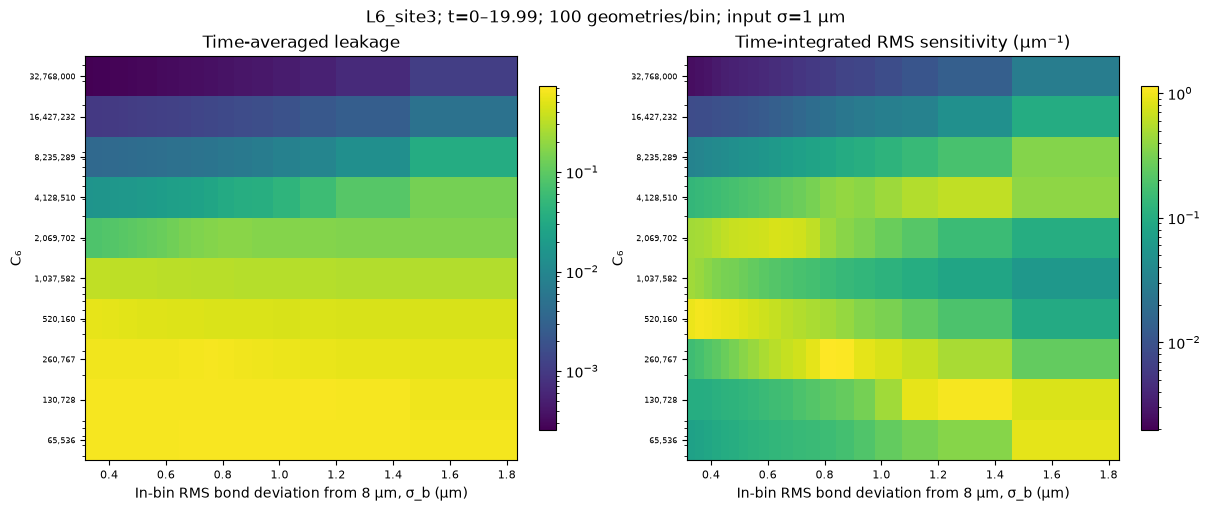

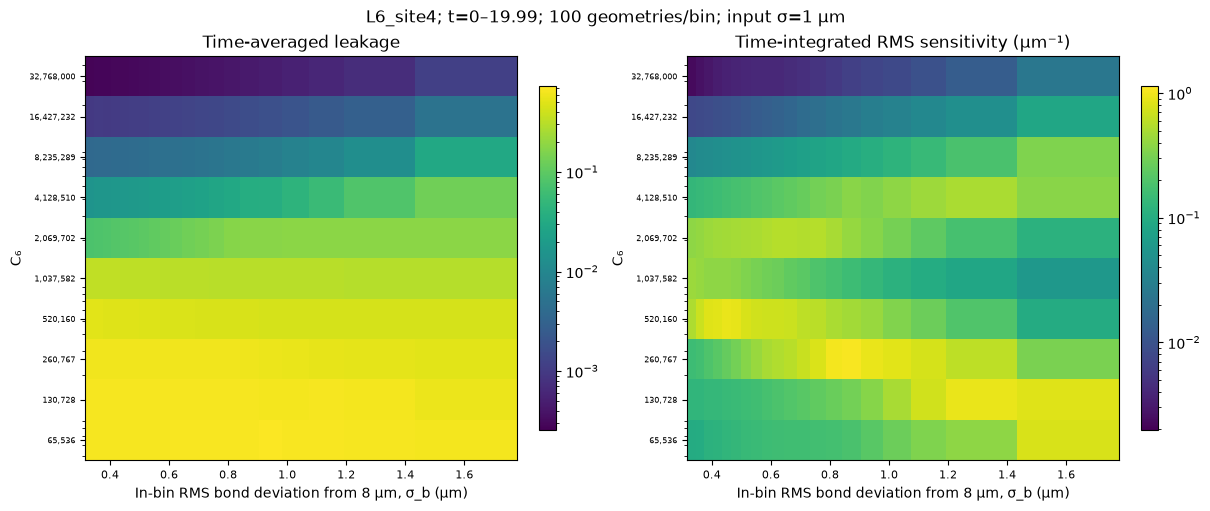

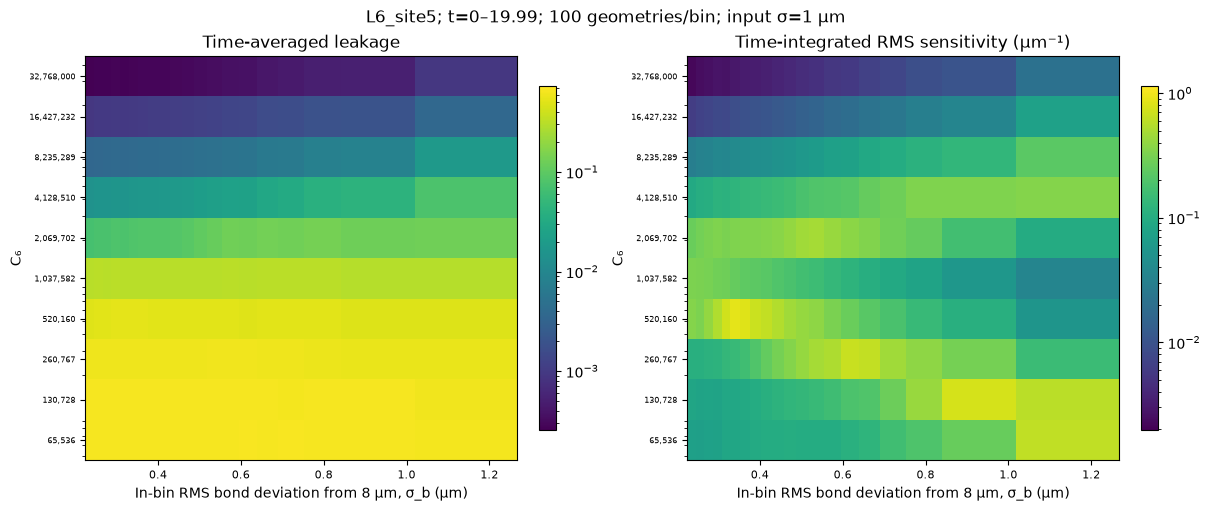

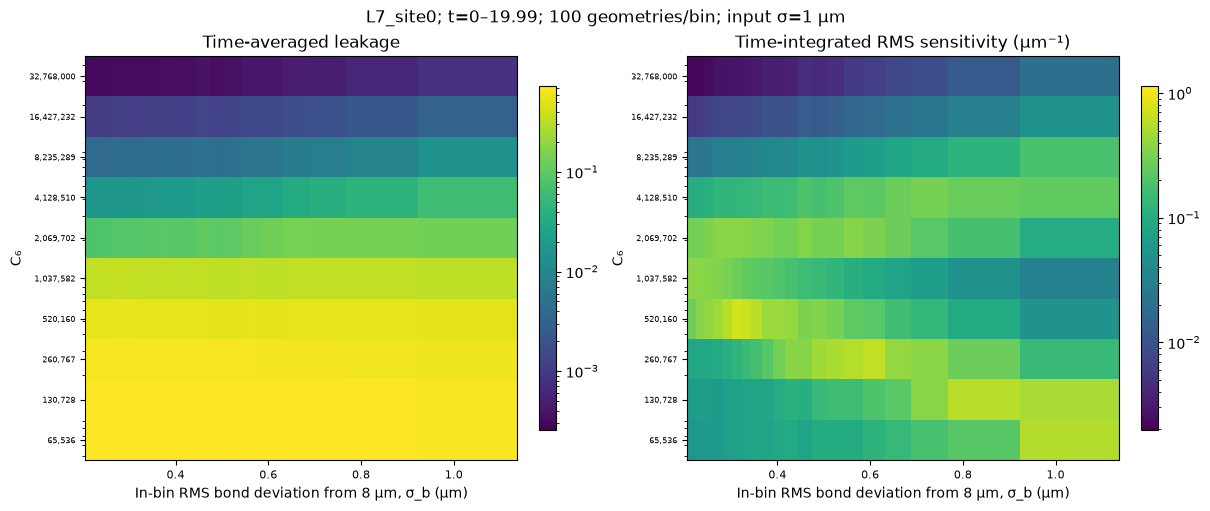

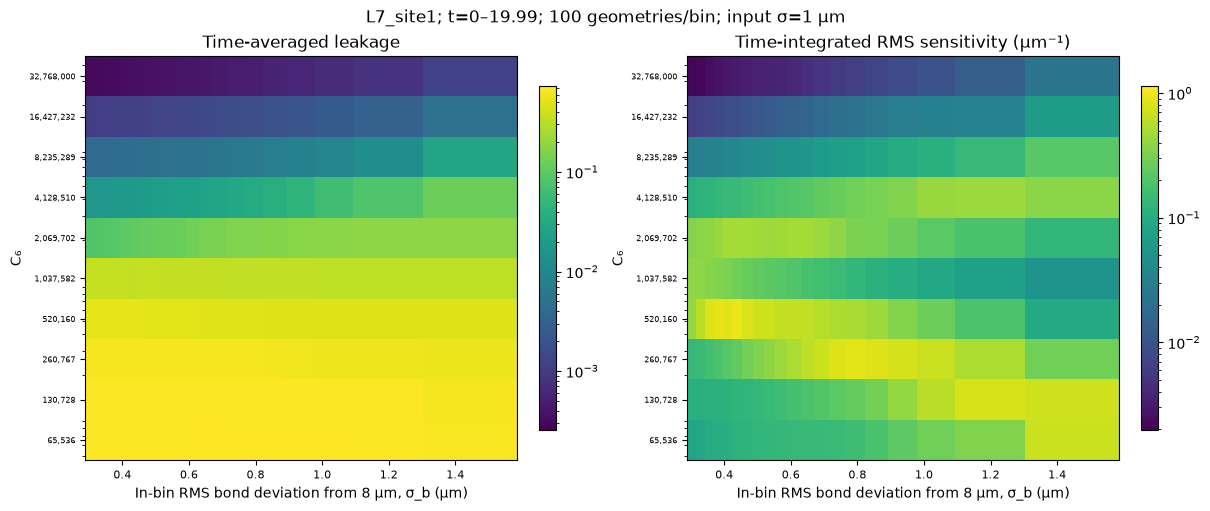

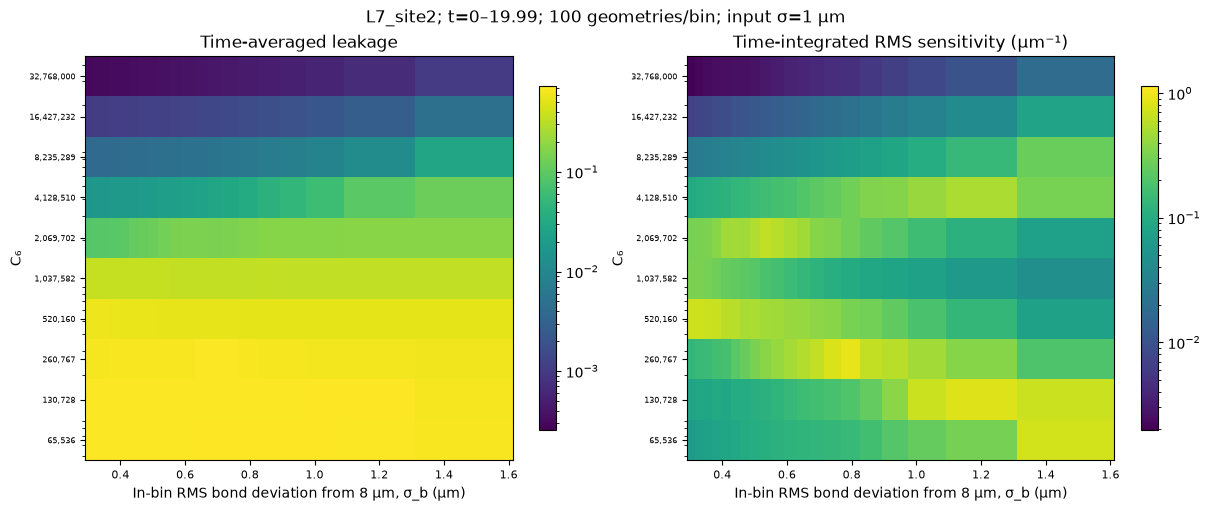

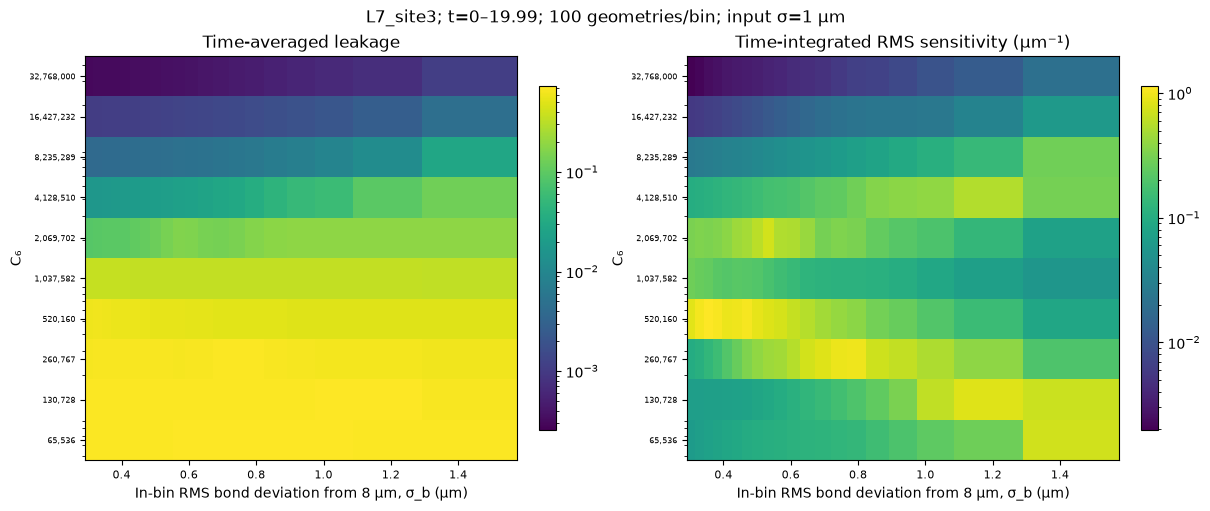

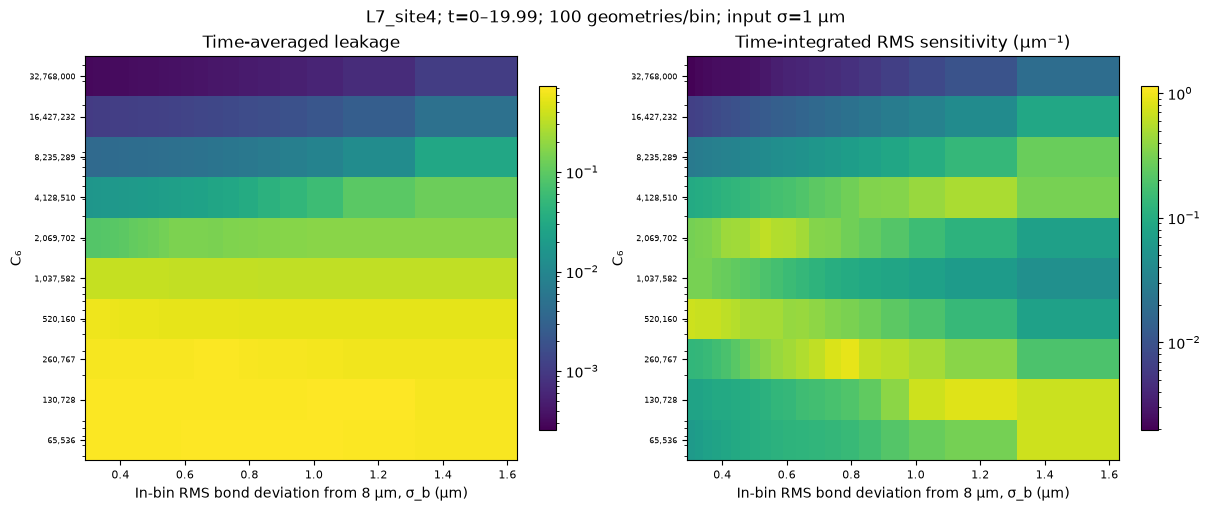

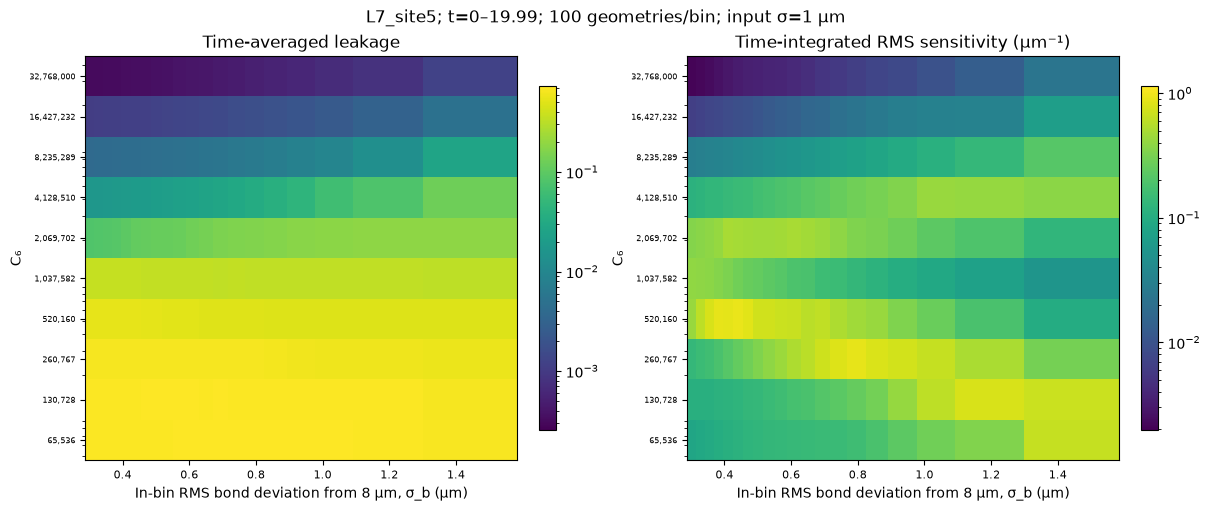

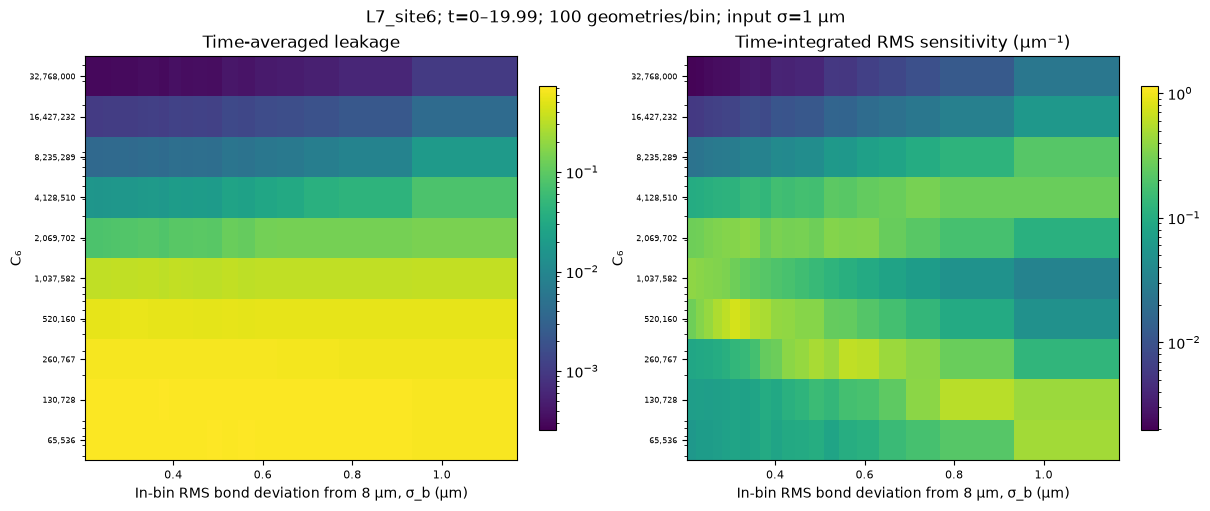

In [3]:
with PdfPages(figdir/'integrated_atlas.pdf') as atlas:
    for key in keys:
        fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
        for ax,metric,norm,title in zip(axes,('mean_leakage_integral','S'),(norm_mean,norm_s),('Time-averaged leakage','Time-integrated RMS sensitivity (µm⁻¹)')):
            image=panel(ax,key,data[key+'_'+metric],norm,title)
            fig.colorbar(image,ax=ax,shrink=.85)
        fig.suptitle(f'{key}; t=0–19.99; 100 geometries/bin; input σ=1 µm')
        save(fig,key+'_integrated',atlas)


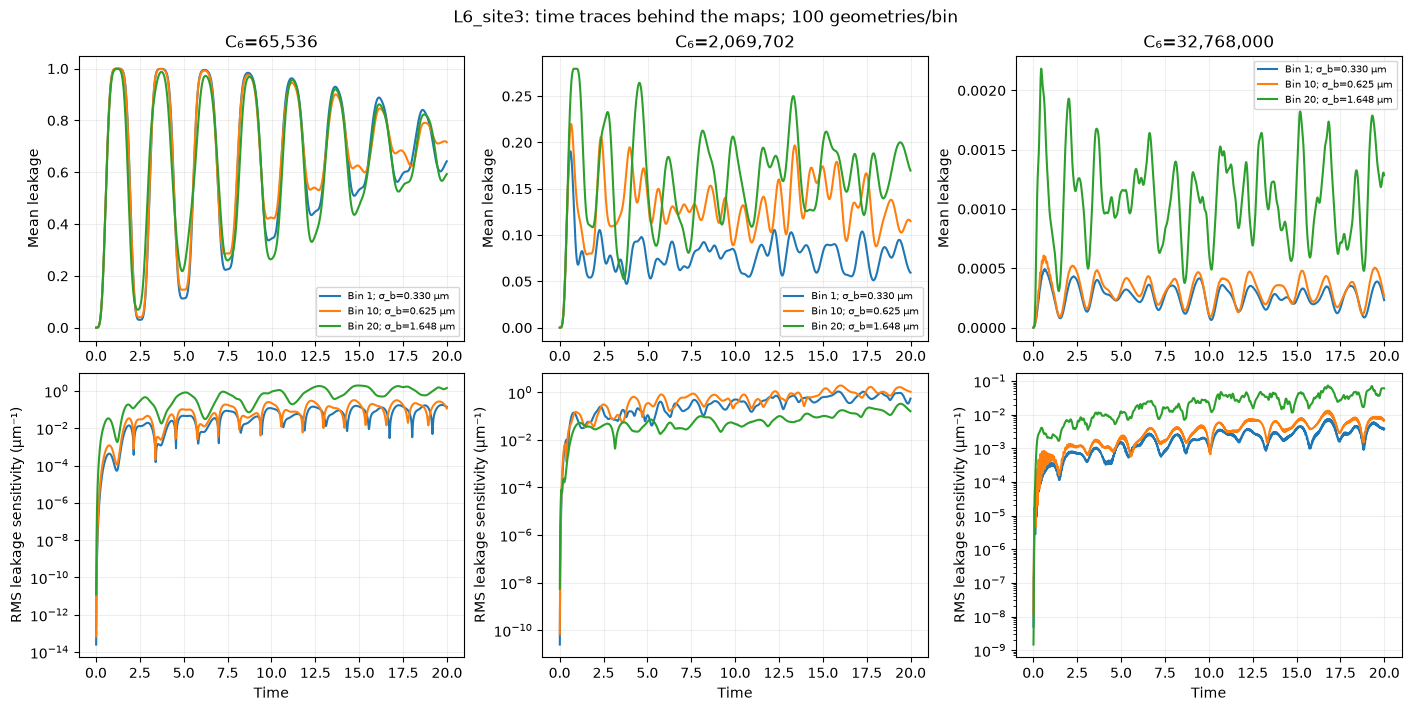

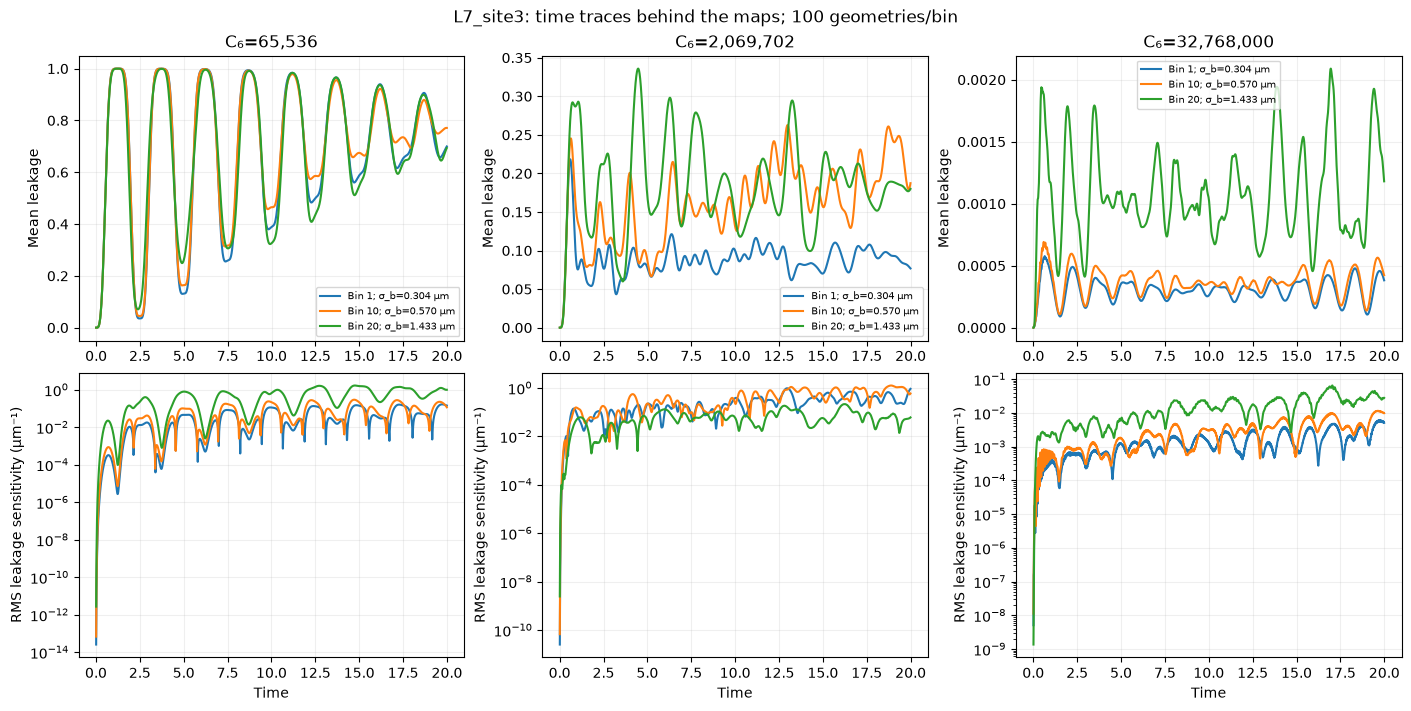

In [4]:
for L in (6,7):
    key=f'L{L}_site{L//2}'
    fig,axes=plt.subplots(2,3,figsize=(14,7),constrained_layout=True)
    for col,ci in enumerate((0,5,9)):
        for m in (0,9,19):
            label=f'Bin {m+1}; σ_b={data[key+"_sigma_b"][m]:.3f} µm'
            axes[0,col].plot(data['times'],data[key+'_mean_leakage'][ci,m],label=label)
            axes[1,col].plot(data['times'][1:],data[key+'_D'][ci,m,1:],label=label)
        axes[0,col].set(title=f'C₆={int(data["c6_values"][ci]):,}',ylabel='Mean leakage')
        axes[1,col].set(yscale='log',xlabel='Time',ylabel='RMS leakage sensitivity (µm⁻¹)')
        for ax in axes[:,col]:ax.grid(alpha=.2)
        axes[0,col].legend(fontsize=7)
    fig.suptitle(f'{key}: time traces behind the maps; 100 geometries/bin')
    save(fig,key+'_time_traces')


### Saved artifacts and next interpretation step

`summary.csv` and `summary.npz` retain every coordinate, signed/absolute rate, numerical mask, and bootstrap interval. Per-site HDF5 files preserve all 100 source geometries, per-geometry leakage and derivatives (float32 storage), double-precision summaries, and accepted finite-difference steps. Computation uses float64/complex128.

These maps describe leakage response. Match them to the completed occupation-sensitivity and model-error study before interpreting them as an explanation of inference. Projected-Hamiltonian and observation-noise controls remain distinct follow-up experiments; they are not results of this scan.